# Discrete Krylov representation of the 3p vertex (`vertex_krylov`)

This notebook is the complete record of results of the `vertex_krylov` task: Step 1 (phases V0, V1, V2, V3a, V3b)
and Step 2 (V3c). It implements and tests Algorithm 2 of the project note **[VD]** *Jacobi matrices and couplings of the 3p
vertex from discrete spectral data*, which takes discrete 2p and 3p PSF weights on one symmetric grid and returns the
Jacobi matrices $\bar{\mathbb J}$, $\bar N$ ($\bar{\mathbb J}_d=-\bar{\mathbb J}^T$), $\mathbb J_B, N_B$,
$\mathbb J_{B^\dagger}, N_{B^\dagger}$, the couplings (VD27) and the self-energy coefficients $\Sigma^{\rm L}$,
$\Sigma^{\rm R}$ (VD4). Inserted into (VD6)–(VD12) they give the Matsubara regular part $\tilde K^{(12)}$ of Lihm's
3p estimator. [VD] Theorem 2 claims exactness for exact Lehmann data at $T>0$ and for binned data with bins
symmetric about zero.

| regime | data source | exactness | section |
|:--|:--|:--|:--|
| Hubbard atom (V1) | HubbardAtom ED, ExactGrid | exact | 2 |
| short Wilson chain (V2a/V2b) | mpNRG ED of the chain, ExactGrid / LogGrid | exact | 3 |
| same chain, untruncated NRG (V3a) | mpNRG NRG, LogGrid | exact | 4 |
| decoupled tail, truncated NRG (V3b) | mpNRG NRG, LogGrid | exact | 5 |
| physical chain, truncated NRG (V3c) | mpNRG NRG, LogGrid | **not** exact; measured (report only) | 6 |

Criteria: the task sheet as amended after the Step-1 review (amendments A1–A3 in `vertex_krylov_STATUS.md`).

**Code.** `src/vertex_krylov.jl` (package `HubbardAtom`, imported as `HA`; depends on `LinearAlgebra` only) and
`mpNRG/test/vertex_krylov_adapter.jl` (data from mpNRG, case runners). The tests
`test/test_vertex_krylov.jl` (V0, V1) and `mpNRG/test/test_vertex_krylov_nrg.jl` (V2, V3a, V3b) assert the same
checks with the same functions.

**Conventions.** $H_{\rm int}=Un_\uparrow n_\downarrow$; $q_\sigma=[d_\sigma,H_{\rm int}]$,
$q^\dagger_\sigma=[H_{\rm int},d^\dagger_\sigma]$, $B=q_{i_1i_2}=\{q_{i_1},d^\dagger_{i_2}\}$ (called `Bq` in code;
`siam(B = …)` is the magnetic field). Channel (↑↓): $(i_1,i_2)=(\downarrow,\downarrow)$, particle chain for
$\sigma=\uparrow$; channel (↑↑): $(i_1,i_2)=(\uparrow,\uparrow)$. Rows $X=(d^\dagger_\sigma,q^\dagger_\sigma)$,
$X_d=(d_\sigma,q_\sigma)$. PSFs follow Kugler Eq. (28), without permutation signs.

In [1]:
using Pkg
Pkg.activate(normpath(joinpath(@__DIR__, "..", "mpNRG", "notebooks")); io = devnull)   # the notebook environment
using MultipointNRG, LinearAlgebra, Printf
import HubbardAtom as HA
using CairoMakie
CairoMakie.activate!(type = "png")
const ROOT = normpath(joinpath(@__DIR__, ".."))
include(joinpath(ROOT, "mpNRG", "test", "helpers.jl"))
include(joinpath(ROOT, "mpNRG", "test", "vertex_krylov_adapter.jl"))
FIG = joinpath(@__DIR__, "figures", "vertex_krylov"); mkpath(FIG)
savefig(name, fig) = (save(joinpath(FIG, name * ".png"), fig; px_per_unit = 2); fig)
fl(x) = max(x, 1e-17)
println("Julia ", VERSION, ", threads ", Threads.nthreads(), ", BLAS threads ", BLAS.get_num_threads())

Julia 1

.13.3, threads 4, BLAS threads 2


## Computation of all cases

All cases of the Step-1 test matrix are computed here, once, by the case runners of the adapter
(`vk_run`, `vk_case_ed`, `vk_case_nrg`), which call `HA.vertex_krylov` and `HA.vk_checks`. The sections below only
display and plot these results. Timings per case are printed and collected in `TIMES`.

In [2]:
R = Dict{String,Any}()      # all results, keyed by case label
# VK_NB_SMOKE=1: structural test run of this notebook on the Nch = 1 data only (the Nch = 2 labels then
# point to the Nch = 1 results). The committed notebook is executed without it.
const SMOKE = get(ENV, "VK_NB_SMOKE", "0") == "1"
NCHS = SMOKE ? (1,) : (1, 2)
TIMES = Dict{String,Any}()
tstart = time()

# --- V1: Hubbard atom, U = 1, εd = -0.3 ------------------------------------------------
const U_AT, ED_AT = 1.0, -0.3
function atom_case(T, chan; σ = :up, h = 0.0, i12 = nothing, rot = nothing)
    m = HA.HubbardAtomModel(U_AT, 1 / T)
    sp = HA.atom_spectrum(m; εd = ED_AT, h = h)
    t0 = time()
    d = HA.discrete_data_atom(m, sp; σ = σ, channel = chan, εd = ED_AT, h = h, i12 = i12, rot = rot)
    tm = Dict{Symbol,Float64}(:data => time() - t0)
    out = vk_run(d; bigfloat = d.N == 1, timings = tm)
    out[:data] = d
    d.N == 1 && rot === nothing && (out[:closed] = HA.atom_closed_form(out[:res]))
    return out
end
for T in (0.1, 0.5), chan in (:updn, :upup)
    R["V1 atom T=$T $chan"] = atom_case(T, chan)
end
for h in (0.0, 0.07)
    R["V1 atom N=2 h=$h"] = atom_case(0.1, :updn; σ = [:up, :dn], i12 = (:dn, :dn), h = h)
    R["V1 atom N=1 up h=$h"] = atom_case(0.1, :updn; σ = :up, h = h)
    R["V1 atom N=1 dn h=$h"] = atom_case(0.1, :upup; σ = :dn, h = h)
end
θ, φ = 0.4, 0.9
ROT = [cos(θ) exp(im * φ) * sin(θ); -exp(-im * φ) * sin(θ) cos(θ)]
R["V1 atom N=2 rotated"] = atom_case(0.1, :updn; σ = [:up, :dn], i12 = (1, 1), h = 0.07, rot = ROT)
@printf("V1 done: %.1f s\n", time() - tstart)

# --- V2: Wilson chain, ED (exact and binned) ---------------------------------------------
KEEP = Set(["V2 Nch=2 B=0.0 updn exact", "V2 Nch=2 B=0.0 updn log", "V2 Nch=1 B=0.0 updn exact", "V3a Nch=2 B=0.0 updn"])
SMOKE && (KEEP = union(KEEP, Set(replace.(collect(KEEP), "Nch=2" => "Nch=1"))))
for Nch in NCHS, field in (0.0, 0.05), chan in (:updn, :upup), gk in (:exact, :log)
    t0 = time()
    k = "V2 Nch=$Nch B=$field $chan $gk"
    # BigFloat particle chain only for Nch ≤ 1 (Nch = 2: R ≈ 2600 rows, L ≈ 2600 steps; deviation in STATUS)
    R[k] = vk_case_ed(Nch, gk, chan; field = field, bigfloat = gk === :exact && Nch == 1, keep = k in KEEP)
    GC.gc()
    @printf("V2 Nch=%d B=%.2f %-5s %-5s: %6.1f s\n", Nch, field, chan, gk, time() - t0)
end
t0 = time()
R["V2 block N=2"] = vk_case_ed(1, :exact, :updn; field = 0.05, σ = [:up, :dn], i12 = (:dn, :dn))
R["V2 block up"] = vk_case_ed(1, :exact, :updn; field = 0.05)
R["V2 block dn"] = vk_case_ed(1, :exact, :upup; field = 0.05, σ = :dn)
@printf("V2 block test: %.1f s\n", time() - t0)
# smallest reproducing case of finding F1 (sites -1..0, 16 states)
R["V2 Nch=0 B=0.0 updn exact"] = vk_case_ed(0, :exact, :updn; bigfloat = true)

# --- V3a: untruncated NRG ----------------------------------------------------------------
for Nch in NCHS, field in (0.0, 0.05), chan in (:updn, :upup)
    t0 = time()
    k = "V3a Nch=$Nch B=$field $chan"
    R[k] = vk_case_nrg(Nch, chan; field = field, keep = k in KEEP)
    GC.gc()
    @printf("V3a Nch=%d B=%.2f %-5s: %6.1f s\n", Nch, field, chan, time() - t0)
end

# --- V3b: decoupled tail, truncated NRG ----------------------------------------------------
for chan in (:updn, :upup)
    t0 = time()
    chs = decoupled_tail(wilson_chains(vk_model(), 3), 1)
    R["V3b $chan"] = vk_case_nrg(3, chan; Nkeep = 40, chains = chs)
    @printf("V3b %-5s: %6.1f s\n", chan, time() - t0)
end

# --- V3c: physical chain, truncated NRG (report only) ---------------------------------------
# NRG data are built by mpNRG/scripts/vertex_krylov_v3c.jl (vk_v3c_data) and cached in
# notebooks/data/vertex_krylov_v3c/; missing cases are built here. Algorithm and checks run here.
using JLD2
include(joinpath(ROOT, "mpNRG", "scripts", "vertex_krylov_v3c.jl"))   # V3C_TS, V3C_NKEEPS, v3c_file, v3c_build_all
v3c_build_all()
for T in V3C_TS, Nk in V3C_NKEEPS, chan in (:updn, :upup)
    t0 = time()
    d = load(v3c_file(T, Nk, chan), "data")
    o = vk_case_v3c(d)
    o[:data] = d
    R["V3c T=$T Nk=$Nk $chan"] = o
    @printf("V3c T=%.0e Nkeep=%3d %-5s: %6.1f s (cached NRG data: %.0f s)\n", T, Nk, chan, time() - t0, d.meta[:time_nrg] + d.meta[:time_data])
end
if SMOKE
    for k in collect(keys(R))
        occursin("Nch=1", k) && (R[replace(k, "Nch=1" => "Nch=2")] = R[k])
    end
end
println("SMOKE = ", SMOKE)
@printf("all cases: %.1f min\n", (time() - tstart) / 60)

V1 done: 54.3 s
V2 Nch=1 B=0.00 updn  exact:   22.7 s


V2 Nch=1 B=0.00 updn  log  :    2.1 s
V2 Nch=1 B=0.00 upup  exact:   13.1 s


V2 Nch=1 B=0.00 upup  log  :    1.2 s
V2 Nch=1 B=0.05 updn  exact:   27.3 s


V2 Nch=1 B=0.05 updn  log  :    1.3 s
V2 Nch=1 B=0.05 upup  exact:   27.4 s


V2 Nch=1 B=0.05 upup  log  :    1.3 s
V2 Nch=2 B=0.00 updn  exact:  529.0 s


V2 Nch=2 B=0.00 updn  log  :    6.1 s
V2 Nch=2 B=0.00 upup  exact:  537.7 s


... (19 outputs left out)

V3c T=1e-04 Nkeep=128 updn :  160.3 s (cached NRG data: 74 s)
V3c T=1e-04 Nkeep=128 upup :  171.2 s (cached NRG data: 75 s)


V3c T=1e-04 Nkeep=256 updn :  186.7 s (cached NRG data: 386 s)
V3c T=1e-04 Nkeep=256 upup :  176.4 s (cached NRG data: 381 s)


V3c T=1e-04 Nkeep=512 updn :  234.0 s (cached NRG data: 1506 s)
V3c T=1e-04 Nkeep=512 upup :  217.8 s (cached NRG data: 1530 s)


SMOKE = false
all cases: 111.7 min


## 0. Summary

The full test matrix of Steps 1 and 2 (task sheet Sec. 6): phase × case × channel × check, with the achieved value, the
tolerance, and pass / FAIL / report. **Guaranteed** tolerances follow from [VD] Theorem 2 (stop rule); "report" means
measured only. Generated from `R` by the same check functions as the tests.

* C1 self-energy (algebraic), C2 Zacinskis cross-check, C3 Dyson, C4 bath leakage, C5 hole symmetry, C6 Gauss
  quadrature, C7 factorization residual, C8 assembly.
* **Amended criteria** (task-sheet amendment of `vertex_krylov_STATUS.md`): (A1) for exact data the guaranteed C4 is
  that of the stabilized particle chain of [VD] Prop. 13 (projector $1-\Omega\Omega^\dagger$); C4 of the unstabilized
  chain ($1-vv^\dagger$) is report. (A2) For exact data the stabilized chain is the default output of Stage 2; the
  unstabilized chain is kept as a diagnostic. (A3) C2: the invariants ($\Sigma^{\rm S}$, spectra and first-block
  weights of $\Omega'$, $S=\bar N^2$, start block) are guaranteed at $10^{-10}$; the Jacobi-block agreement
  (`n_agree`, finding F2) is report.
* V3c (physical chain, truncated NRG) is report only, every check.
* C8 is relative to $\max|K^{\rm direct}|$, except where $K^{\rm direct}\equiv0$ (marked `†`, see deviation 4 of
  `vertex_krylov_STATUS.md`).

In [3]:
ROWS = Any[]
function row!(phase, case, chan, check, val, tol; note = "")
    st = tol === nothing ? "report" : isnan(val) ? "n/a" : (val ≤ tol ? "pass" : "FAIL")
    push!(ROWS, (phase = phase, case = case, chan = chan, check = check, value = val, tol = tol, status = st, note = note))
end
TOL = Dict("V1" => (C1 = 1e-11, C2 = 1e-10, C34 = 1e-11, C56 = 1e-12, C7 = 1e-11, C8 = 1e-10),
           "V2a" => (C1 = 1e-10, C2 = 1e-10, C34 = 1e-9, C56 = 1e-12, C7 = 1e-10, C8 = 1e-9),
           "V2b" => (C1 = 1e-10, C2 = 1e-10, C34 = nothing, C56 = 1e-12, C7 = 1e-10, C8 = 1e-9),
           "V3a" => (C1 = 1e-10, C2 = 1e-10, C34 = nothing, C56 = 1e-11, C7 = 1e-9, C8 = 1e-8),
           "V3b" => (C1 = 1e-10, C2 = 1e-10, C34 = nothing, C56 = 1e-11, C7 = 1e-9, C8 = 1e-8),
           "V3c" => (C1 = nothing, C2 = nothing, C34 = nothing, C56 = nothing, C7 = nothing, C8 = nothing))
function rows_for!(phase, case, chan, out)
    t = TOL[phase]; c = out[:checks]
    row!(phase, case, chan, "C1", c[:C1], t.C1)
    row!(phase, case, chan, "C2", c[:C2], t.C2)
    haskey(c, :zac) && row!(phase, case, chan, "C2 blocks n_agree/L", c[:zac].n_agree / c[:zac].L_chain, nothing)
    row!(phase, case, chan, "C3", c[:C3], t.C34)
    if haskey(out, :unstab)          # exact data: the default chain is the stabilized one (A1, A2)
        row!(phase, case, chan, "C4 (stabilized, default)", c[:C4], t.C34)
        row!(phase, case, chan, "C4 (unstabilized, diagnostic)", out[:unstab].C4, nothing)
    else
        row!(phase, case, chan, "C4", c[:C4], t.C34)
    end
    haskey(out, :big) && row!(phase, case, chan, "C4 (BigFloat, default chain)", out[:big].C4, t.C34)
    haskey(out, :big_unstab) && row!(phase, case, chan, "C4 (BigFloat, unstabilized)", out[:big_unstab].C4, nothing)
    row!(phase, case, chan, "C5", c[:C5], t.C56)
    row!(phase, case, chan, "C6", c[:C6], t.C56)
    row!(phase, case, chan, "C7", c[:C7], t.C7)
    row!(phase, case, chan, "C8", c[:C8], t.C8; note = c[:C8_parts].degenerate ? "†" : "")
end
chs(s) = s === :updn ? "(↑↓)" : "(↑↑)"
for T in (0.1, 0.5), chan in (:updn, :upup)
    rows_for!("V1", "atom T=$T", chs(chan), R["V1 atom T=$T $chan"])
    cf = R["V1 atom T=$T $chan"][:closed]
    row!("V1", "atom T=$T", chs(chan), "closed form |ΔJ̄|,|ΔN̄²|,|Δσ|", max(cf.J_err, cf.N2_err, cf.σ_err), 1e-12)
    row!("V1", "atom T=$T", chs(chan), "chain length 1, resid", cf.L == 1 ? cf.resid : Inf, 1e-12)
end
for h in (0.0, 0.07)
    rows_for!("V1", "atom N=2 h=$h", "B=q↓↓", R["V1 atom N=2 h=$h"])
end
rows_for!("V1", "atom N=2 rotated", "B=q′₁₁", R["V1 atom N=2 rotated"])
for Nch in (1, 2), field in (0.0, 0.05), chan in (:updn, :upup)
    case = "chain Nch=$Nch B=$field"
    rows_for!("V2a", case, chs(chan), R["V2 Nch=$Nch B=$field $chan exact"])
end
for Nch in (1, 2), field in (0.0, 0.05), chan in (:updn, :upup)
    rows_for!("V2b", "chain Nch=$Nch B=$field", chs(chan), R["V2 Nch=$Nch B=$field $chan log"])
end
rows_for!("V2a", "N=2 block, Nch=1 B=0.05", "B=q↓↓", R["V2 block N=2"])
for Nch in (1, 2), field in (0.0, 0.05), chan in (:updn, :upup)
    o = R["V3a Nch=$Nch B=$field $chan"]
    rows_for!("V3a", "NRG Nch=$Nch B=$field", chs(chan), o)
    row!("V3a", "NRG Nch=$Nch B=$field", chs(chan), "data vs V2b max|ΔW̃|,|Δs|", max(o[:diff].W, o[:diff].wB, o[:diff].s), nothing)
end
for chan in (:updn, :upup)
    o = R["V3b $chan"]
    rows_for!("V3b", "decoupled tail Nkeep=40", chs(chan), o)
    row!("V3b", "decoupled tail Nkeep=40", chs(chan), "data vs ED max|ΔW̃|,|Δs|", max(o[:diff].W, o[:diff].wB, o[:diff].s), nothing)
end
for T in V3C_TS, Nk in V3C_NKEEPS, chan in (:updn, :upup)
    o = R["V3c T=$T Nk=$Nk $chan"]; case = @sprintf("T=%.0e Nkeep=%d", T, Nk)
    rows_for!("V3c", case, chs(chan), o)
    ref = R["V3c T=$T Nk=512 $chan"][:checks][:box]; bx = o[:checks][:box]; m_ = .!isnan.(real.(bx.Kt))
    row!("V3c", case, chs(chan), "K̃ vs Nkeep=512 (rel.)", maximum(abs, bx.Kt[m_] - ref.Kt[m_]) / maximum(abs, ref.Kt[m_]), nothing)
end
@printf("%-5s %-26s %-7s %-30s %11s %9s  %s\n", "phase", "case", "channel", "check", "value", "tol", "status")
for r in ROWS
    @printf("%-5s %-26s %-7s %-30s %11.2e %9s  %s%s\n", r.phase, r.case, r.chan, r.check, r.value,
            r.tol === nothing ? "—" : @sprintf("%.0e", r.tol), r.status, r.note)
end
FAILS = filter(r -> r.status == "FAIL", ROWS)
println("\n", length(ROWS), " rows: ", count(r -> r.status == "pass", ROWS), " pass, ", length(FAILS), " FAIL, ",
        count(r -> r.status == "report", ROWS), " report")

phase case                       channel check                                value       tol  status
V1    atom T=0.1                 (↑↓)    C1                                7.98e-16     1e-11  pass


V1    atom T=0.1                 (↑↓)    C2                                2.83e-14     1e-10  pass
V1    atom T=0.1                 (↑↓)    C2 blocks n_agree/L               1.00e+00         —  report
V1    atom T=0.1                 (↑↓)    C3                                1.68e-15     1e-11  pass
V1    atom T=0.1                 (↑↓)    C4 (stabilized, default)          2.22e-16     1e-11  pass
V1    atom T=0.1                 (↑↓)    C4 (unstabilized, diagnostic)     2.22e-16         —  report
V1    atom T=0.1                 (↑↓)    C4 (BigFloat, default chain)      1.46e-16     1e-11  pass
V1    atom T=0.1                 (↑↓)    C4 (BigFloat, unstabilized)       1.46e-16         —  report
V1    atom T=0.1                 (↑↓)    C5                                0.00e+00     1e-12  pass
V1    atom T=0.1                 (↑↓)    C6                                1.05e-16     1e-12  pass
V1    atom T=0.1                 (↑↓)    C7                                3.42e-16     1e-11 

V2a   chain Nch=1 B=0.0          (↑↑)    C2                                1.12e-13     1e-10  pass
V2a   chain Nch=1 B=0.0          (↑↑)    C2 blocks n_agree/L               4.48e-01         —  report
V2a   chain Nch=1 B=0.0          (↑↑)    C3                                4.38e-14     1e-09  pass
V2a   chain Nch=1 B=0.0          (↑↑)    C4 (stabilized, default)          1.20e-14     1e-09  pass
V2a   chain Nch=1 B=0.0          (↑↑)    C4 (unstabilized, diagnostic)     8.30e-01         —  report
V2a   chain Nch=1 B=0.0          (↑↑)    C4 (BigFloat, default chain)      1.28e-14     1e-09  pass
V2a   chain Nch=1 B=0.0          (↑↑)    C4 (BigFloat, unstabilized)       8.14e-01         —  report
V2a   chain Nch=1 B=0.0          (↑↑)    C5                                0.00e+00     1e-12  pass
V2a   chain Nch=1 B=0.0          (↑↑)    C6                                7.68e-16     1e-12  pass
V2a   chain Nch=1 B=0.0          (↑↑)    C7                                8.15e-16     1e-10 

V2b   chain Nch=1 B=0.05         (↑↓)    C5                                0.00e+00     1e-12  pass
V2b   chain Nch=1 B=0.05         (↑↓)    C6                                8.95e-16     1e-12  pass
V2b   chain Nch=1 B=0.05         (↑↓)    C7                                2.40e-14     1e-10  pass
V2b   chain Nch=1 B=0.05         (↑↓)    C8                                2.75e-14     1e-09  pass
V2b   chain Nch=1 B=0.05         (↑↑)    C1                                1.76e-15     1e-10  pass
V2b   chain Nch=1 B=0.05         (↑↑)    C2                                5.64e-14     1e-10  pass
V2b   chain Nch=1 B=0.05         (↑↑)    C2 blocks n_agree/L               5.15e-01         —  report
V2b   chain Nch=1 B=0.05         (↑↑)    C3                                2.39e-01         —  report
V2b   chain Nch=1 B=0.05         (↑↑)    C4                                5.73e-01         —  report
V2b   chain Nch=1 B=0.05         (↑↑)    C5                                0.00e+00     1e-12 

V3a   NRG Nch=1 B=0.05           (↑↑)    data vs V2b max|ΔW̃|,|Δs|          1.67e-15         —  report
V3a   NRG Nch=2 B=0.0            (↑↓)    C1                                1.68e-15     1e-10  pass
V3a   NRG Nch=2 B=0.0            (↑↓)    C2                                3.21e-14     1e-10  pass
V3a   NRG Nch=2 B=0.0            (↑↓)    C2 blocks n_agree/L               2.04e-01         —  report
V3a   NRG Nch=2 B=0.0            (↑↓)    C3                                4.54e-01         —  report
V3a   NRG Nch=2 B=0.0            (↑↓)    C4                                3.76e-01         —  report
V3a   NRG Nch=2 B=0.0            (↑↓)    C5                                0.00e+00     1e-11  pass
V3a   NRG Nch=2 B=0.0            (↑↓)    C6                                4.40e-16     1e-11  pass
V3a   NRG Nch=2 B=0.0            (↑↓)    C7                                5.71e-16     1e-09  pass
V3a   NRG Nch=2 B=0.0            (↑↓)    C8                                2.13e-14     1e-

V3c   T=1e-02 Nkeep=128          (↑↑)    C2 blocks n_agree/L               7.76e-02         —  report
V3c   T=1e-02 Nkeep=128          (↑↑)    C3                                3.90e-01         —  report
V3c   T=1e-02 Nkeep=128          (↑↑)    C4                                4.30e-01         —  report
V3c   T=1e-02 Nkeep=128          (↑↑)    C4 (BigFloat, default chain)      4.30e-01         —  report
V3c   T=1e-02 Nkeep=128          (↑↑)    C5                                0.00e+00         —  report
V3c   T=1e-02 Nkeep=128          (↑↑)    C6                                1.81e-15         —  report
V3c   T=1e-02 Nkeep=128          (↑↑)    C7                                2.28e-03         —  report
V3c   T=1e-02 Nkeep=128          (↑↑)    C8                                4.62e-04         —  report
V3c   T=1e-02 Nkeep=128          (↑↑)    K̃ vs Nkeep=512 (rel.)             2.28e-02         —  report
V3c   T=1e-02 Nkeep=256          (↑↓)    C1                                2.30e-

V3c   T=1e-04 Nkeep=128          (↑↑)    K̃ vs Nkeep=512 (rel.)             5.92e-03         —  report
V3c   T=1e-04 Nkeep=256          (↑↓)    C1                                3.37e-05         —  report
V3c   T=1e-04 Nkeep=256          (↑↓)    C2                                3.43e-14         —  report
V3c   T=1e-04 Nkeep=256          (↑↓)    C2 blocks n_agree/L               6.04e-02         —  report
V3c   T=1e-04 Nkeep=256          (↑↓)    C3                                2.60e-01         —  report
V3c   T=1e-04 Nkeep=256          (↑↓)    C4                                6.43e-01         —  report
V3c   T=1e-04 Nkeep=256          (↑↓)    C4 (BigFloat, default chain)      6.43e-01         —  report
V3c   T=1e-04 Nkeep=256          (↑↓)    C5                                0.00e+00         —  report
V3c   T=1e-04 Nkeep=256          (↑↓)    C6                                2.59e-06         —  report
V3c   T=1e-04 Nkeep=256          (↑↓)    C7                                2.53e-

532 rows: 252 pass, 0 FAIL, 280 report


### Failures and open findings

Generated list of all FAIL rows, followed by the findings of Sec. 7.

In [4]:
if isempty(FAILS)
    println("Failures: none")
else
    println("Failures (guaranteed check beyond tolerance):")
    for r in FAILS
        @printf("  %-5s %-26s %-7s %-18s %.2e > %.0e\n", r.phase, r.case, r.chan, r.check, r.value, r.tol)
    end
    fc = unique([r.check for r in FAILS])
    println("checks affected: ", join(fc, ", "))
end
println("\nOpen findings (Sec. 7): F1 (the unstabilized chain leaks, C4 report under A1); F2 (C2 Jacobi blocks agree only on",
        " leading blocks, report under A3); F3 (K ≡ 0 in the atom's (↑↑) channel); V3c (Sec. 6, report only).")

Failures: none

Open findings (Sec. 7): F1 (the unstabilized chain leaks, C4 report under A1); F2 (C2 Jacobi blocks agree only on leading blocks, report under A3); F3 (K ≡ 0 in the atom's (↑↑) channel); V3c (Sec. 6, report only).


## 1. Conventions

Checked before any comparison is trusted (task sheet Secs. 2.2, 2.3, 2.5, 5.1):

1. PSF convention (Kugler Eq. (28)) on a 2p example by explicit Lehmann summation: expected agreement to rounding.
2. ζ signs of $(p_1,\dots,p_6)$ for $(q_{12},T^{(3)},T^{(4)})$ from `HA.permutation_sign(p, [false,true,true])`:
   expected $(+,-,+,-,-,+)$.
3. Odd bin map, $c(-E)=-c(E)$, for the ExactGrid and the LogGrid.
4. The (I3) index map with the barred indices, with one worked entry.
5. The frequency convention of `regular_sum`: `z = [iω12, iω3, iω4]` must equal the [3p] Sec. III.3 form
   $\sum_p\zeta^pF_p[\vec{\mathcal O}_p](i\alpha_{\bar1},-i\alpha_{\bar3})$, evaluated independently with the
   Liouvillian superoperator in the eigenbasis (`HA.liouvillian_regular`).

In [5]:
m = HA.HubbardAtomModel(U_AT, 10.0); sp = HA.atom_spectrum(m; εd = ED_AT)
ops = HA.vk_atom_operators(m; spins = [:up], i12 = (:dn, :dn))
@printf("1. PSF convention: max |Δw| = %.1e (S[d,d†]), %.1e (S[q,d†]), %.1e (S[B†,B])\n",
        HA.psf_convention_check(sp, ops.Xd[1], ops.X[1]), HA.psf_convention_check(sp, ops.Xd[2], ops.X[1]),
        HA.psf_convention_check(sp, ops.Bqd, ops.Bq))
println("2. ζ(p1..p6) = ", HA.vk_zeta(), "   expected [1, -1, 1, -1, -1, 1]: ", HA.vk_zeta() == [1, -1, 1, -1, -1, 1])
ge = R["V2 Nch=1 B=0.0 updn exact"][:data].meta[:grid]
bg, _ = vk_loggrid(vk_grid())
xs = vcat(10.0 .^ range(-7, 1.5; length = 400), [0.0, 1e-15, 3e-14])
println("3. odd bin map: LogGrid ", all(x -> HA.bin_of(bg, -x) == bg.bar[HA.bin_of(bg, x)], xs),
        "; ExactGrid (V2a Nch=1, ", length(ge.b), " bins) ", all(β -> HA.bin_of(ge, -ge.b[β]) == ge.bar[β], eachindex(ge.b)),
        "; within-cluster spread ", @sprintf("%.1e", ge.spread))

1. PSF convention: max |Δw| = 0.0e+00 (S[d,d†]), 0.0e+00 (S[q,d†]), 0.0e+00 (S[B†,B])
2. ζ(p1..p6) = 

[1, -1, 1, -1, -1, 1]   expected [1, -1, 1, -1, -1, 1]: true
3. odd bin map: LogGrid 

true; ExactGrid (V2a Nch=1, 625 bins) true; within-cluster spread 2.6e-15


In [6]:
# 4. (I3) worked entry: s2[α,β][a,b] = S(ᾱ, β̄)[X_a, B, X_b†] for the atom, channel (↑↑) (B = q↑↑), T = 0.1
#    (in the (↑↓) channel of the atom the family s2 vanishes identically)
d = R["V1 atom T=0.1 upup"][:data]
ops = HA.vk_atom_operators(m; spins = [:up], i12 = (:up, :up))
println("(I3): s1 = S(α,β)[X_a†,B,X_b], s2 = S(ᾱ,β̄)[X_a,B,X_b†], s3 = S(α,β)[B,x,X_b], s4 = S(ᾱ,β)[X_a,x,B],")
println("      s5 = S(α,β̄)[B,y,X_b†], s6 = S(α,β)[X_a†,y,B]")
(k, blk) = first(sort(collect(d.s2); by = first))
a, b = Tuple(argmax(abs.(blk)))
α, β = k
names = ["d†", "q†"]
@printf("worked entry: s2[(α,β) = (%d,%d)][a,b] = [%s,%s] = %.6f, i.e. the PSF S[%s, B, %s] at (ε1,ε2) = (b_ᾱ, b_β̄) = (%.4f, %.4f)\n",
        α, β, names[a], names[b], real(blk[a, b]), names[a], names[b] == "d†" ? "d" : "q", d.b[d.bar[α]], d.b[d.bar[β]])
ts = HA.psf(sp, (ops.X[a], ops.Bq, ops.Xd[b]))
w = sum(t.weight for t in ts if abs(t.position[1] - d.b[d.bar[α]]) < 1e-10 && abs(t.position[2] - d.b[d.bar[β]]) < 1e-10; init = 0.0im)
@printf("direct PSF sum at that position: %.6f  (difference %.1e)\n", real(w), abs(w - blk[a, b]))

(I3): s1 = S(α,β)[X_a†,B,X_b], s2 = S(ᾱ,β̄)[X_a,B,X_b†], s3 = S(α,β)[B,x,X_b], s4 = S(ᾱ,β)[X_a,x,B],
      s5 = S(α,β̄)[B,y,X_b†], s6 = S(α,β)[X_a†,y,B]
worked entry: s2[(α,β) = (5,5)][a,b] = [d†,d†] = 0.000445, i.e. the PSF S[d†, B, d] at (ε1,ε2) = (b_ᾱ, b_β̄) = (-0.7000, -0.7000)
direct PSF sum at that position: 0.000445  (difference 0.0e+00)


In [7]:
# 5. regular_sum frequency convention vs [3p] Sec. III.3 (Liouvillian form)
err = 0.0
for (n3, n4) in ((0, 0), (2, -5), (-3, 1), (4, 4)), (x, y) in ((ops.q[1], ops.X[2]), (ops.d[1], ops.X[1]), (ops.q[1], ops.X[1]))
    ω3 = HA.vk_fermionic(n3, 0.1); ω4 = HA.vk_fermionic(n4, 0.1); ω12 = -ω3 - ω4
    rs = HA.regular_sum(sp, (ops.Bq, x, y), ComplexF64[im * ω12, im * ω3, im * ω4]; is_fermionic = [false, true, true])
    global err = max(err, abs(rs - HA.liouvillian_regular(sp, (ops.Bq, x, y), [ω12, ω3, ω4])))
end
@printf("5. regular_sum(z = [iω12, iω3, iω4]) vs Σ_p ζ^p F_p(iα_p̄1, -iα_p̄3): max |Δ| = %.1e over 12 points\n", err)

5. regular_sum(z = [iω12, iω3, iω4]) vs Σ_p ζ^p F_p(iα_p̄1, -iα_p̄3): max |Δ| = 6.9e-17 over 12 points


## 2. Hubbard atom (V1)

$U=1$, $\varepsilon_d=-0.3$, $T\in\{0.1,0.5\}$, HubbardAtom ED on the ExactGrid. Expected: the closed-form one-level
chain of [VD] App. F, $\bar{\mathbb J}=\varepsilon_\sigma+U(1-n)$, $\bar N^2=U^2n(1-n)$, $\sigma=Un$,
$n=\langle n_{\bar\sigma}\rangle$, chain length 1; all checks to the V1 tolerances. The bosonic legs of the atom are
trivial ($B$ is a conserved density, $\mathbb J_B$ is $1\times1$ with entry 0). In the (↑↑) channel
$B=Un_\downarrow$ commutes with $H$, $d_\uparrow$, $q_\uparrow$, so $K^{(12)}\equiv0$ at $\omega_{12}\neq0$ while
the six permutation terms are $O(1)$; C8 is then measured on the scale of the permutation terms (also shown: the
per-permutation agreement, which holds term by term).

In [8]:
@printf("%-26s %3s %10s %10s %10s %10s %9s %9s %9s %9s %9s %9s %9s %9s\n", "case", "L", "J̄", "J̄ closed", "N̄²", "N̄² closed",
        "C1", "C2", "C3", "C4", "C5", "C6", "C7", "C8")
for T in (0.1, 0.5), chan in (:updn, :upup)
    o = R["V1 atom T=$T $chan"]; c = o[:checks]; cf = o[:closed]; ch = o[:res].ch
    @printf("%-26s %3d %10.6f %10.6f %10.6f %10.6f %9.1e %9.1e %9.1e %9.1e %9.1e %9.1e %9.1e %9.1e%s\n", "T=$T $(chs(chan))",
            cf.L, real(ch.Jbar.eps[1][1]), cf.J, real(ch.Nbar[1])^2, cf.N2, c[:C1], c[:C2], c[:C3], c[:C4], c[:C5], c[:C6],
            c[:C7], c[:C8], c[:C8_parts].degenerate ? " †" : "")
end
println("\nC8 detail (abs = max|K̃ - K^direct|, perm = per-permutation error / max|K_p|):")
for T in (0.1, 0.5), chan in (:updn, :upup)
    p = R["V1 atom T=$T $chan"][:checks][:C8_parts]
    @printf("  T=%-4s %s: max|K^direct| = %.2e, max|K_p| = %.2e, abs = %.1e, rel = %.1e, rel_perm = %.1e, perm = %.1e\n",
            T, chs(chan), p.maxKd, p.maxKp, p.abs, p.rel, p.rel_perm, p.perm)
end
println("\nBigFloat (128 bit) particle chain vs Float64: ",
        join([@sprintf("T=%s %s: |ΔJ̄| = %.1e", T, chs(ch), maximum(R["V1 atom T=$T $ch"][:big].dev)) for T in (0.1, 0.5), ch in (:updn, :upup)], "; "))

case                         L          J̄   J̄ closed         N̄²  N̄² closed        C1        C2        C3        C4        C5        C6        C7        C8
T=0.1 (↑↓)                   1   0.211917   0.211917   0.249858   0.249858   8.0e-16   2.8e-14   1.7e-15   2.2e-16   0.0e+00   1.0e-16   3.4e-16   3.8e-16


T=0.1 (↑↑)                   1   0.211917   0.211917   0.249858   0.249858   8.0e-16   2.8e-14   1.7e-15   2.2e-16   0.0e+00   1.0e-16   3.7e-16   3.2e-16 †
T=0.5 (↑↓)                   1   0.254056   0.254056   0.247078   0.247078   5.5e-16   5.4e-15   5.7e-15   1.1e-16   0.0e+00   1.1e-16   1.6e-16   1.5e-16
T=0.5 (↑↑)                   1   0.254056   0.254056   0.247078   0.247078   5.5e-16   5.4e-15   5.7e-15   1.1e-16   0.0e+00   1.1e-16   1.6e-16   1.5e-16 †

C8 detail (abs = max|K̃ - K^direct|, perm = per-permutation error / max|K_p|):
  T=0.1  (↑↓): max|K^direct| = 1.74e+00, max|K_p| = 9.30e-01, abs = 6.7e-16, rel = 3.8e-16, rel_perm = 7.2e-16, perm = 3.7e-16


  T=0.1  (↑↑): max|K^direct| = 1.79e-16, max|K_p| = 1.09e+00, abs = 3.4e-16, rel = 1.9e+00, rel_perm = 3.2e-16, perm = 2.9e-16
  T=0.5  (↑↓): max|K^direct| = 9.76e-02, max|K_p| = 5.88e-02, abs = 1.4e-17, rel = 1.5e-16, rel_perm = 2.4e-16, perm = 1.2e-16
  T=0.5  (↑↑): max|K^direct| = 3.74e-18, max|K_p| = 4.34e-02, abs = 6.3e-18, rel = 1.7e+00, rel_perm = 1.5e-16, perm = 2.5e-16

BigFloat (128 bit) particle chain vs Float64: 

T=0.1 (↑↓): |ΔJ̄| = 8.2e-17; T=0.5 (↑↓): |ΔJ̄| = 2.7e-17; T=0.1 (↑↑): |ΔJ̄| = 8.2e-17; T=0.5 (↑↑): |ΔJ̄| = 2.7e-17


In [9]:
# N = 2 block test: spin-unresolved atom, X = (d†↑, d†↓, q†↑, q†↓), B = q↓↓, vs the N = 1 runs
for h in (0.0, 0.07)
    o2 = R["V1 atom N=2 h=$h"]; ou = R["V1 atom N=1 up h=$h"]; od = R["V1 atom N=1 dn h=$h"]
    b2 = o2[:checks][:box]; bu = ou[:checks][:box]; bd = od[:checks][:box]
    m_ = .!isnan.(real.(bu.Kd))
    zs = HA.vk_testpoints(o2[:data])
    dΣ = maximum(z -> maximum(abs, HA.sigma_chain(o2[:res].ch, z) - Diagonal([HA.sigma_chain(ou[:res].ch, z)[1], HA.sigma_chain(od[:res].ch, z)[1]])), zs)
    @printf("h = %.2f: max|K̃↑↑(N=2) - K̃(N=1,↑)| = %.1e, max|K̃↓↓(N=2) - K̃(N=1,↓)| = %.1e, max|K̃ off-diag| = %.1e, max|ΔΣ^S| = %.1e; C1..C8: %s\n",
            h, maximum(abs, b2.Kt[1, 1, :, :][m_] - bu.Kt[m_]), maximum(abs, b2.Kt[2, 2, :, :][m_] - bd.Kt[m_]),
            max(maximum(abs, b2.Kt[1, 2, :, :][m_]), maximum(abs, b2.Kt[2, 1, :, :][m_])), dΣ,
            join([@sprintf("%.0e", o2[:checks][k]) for k in (:C1, :C2, :C3, :C4, :C5, :C6, :C7, :C8)], " "))
end
o = R["V1 atom N=2 rotated"]; bx = o[:checks][:box]; m_ = .!isnan.(real.(bx.Kd[1, 1, :, :]))
@printf("rotated complex orbitals (h = 0.07): max|K12 - K21| = %.2f (asymmetric, exercises the p2 transposition); C8 = %.1e, C1 = %.1e, C7 = %.1e\n",
        maximum(abs, bx.Kd[1, 2, :, :][m_] - bx.Kd[2, 1, :, :][m_]), o[:checks][:C8], o[:checks][:C1], o[:checks][:C7])

h = 0.00: max|K̃↑↑(N=2) - K̃(N=1,↑)| = 4.0e-16, max|K̃↓↓(N=2) - K̃(N=1,↓)| = 1.7e-16, max|K̃ off-diag| = 0.0e+00, max|ΔΣ^S| = 4.5e-15; C1..C8: 9e-16 2e-14 2e-15 0e+00 0e+00 1e-16 7e-16 2e-16
h = 0.07: max|K̃↑↑(N=2) - K̃(N=1,↑)| = 4.5e-16, max|K̃↓↓(N=2) - K̃(N=1,↓)| = 7.1e-16, max|K̃ off-diag| = 0.0e+00, max|ΔΣ^S| = 1.7e-15; C1..C8: 2e-15 3e-14 2e-15 3e-16 0e+00 2e-16 5e-16 8e-16


rotated complex orbitals (h = 0.07): max|K12 - K21| = 0.36 (asymmetric, exercises the p2 transposition); C8 = 4.6e-16, C1 = 1.1e-15, C7 = 8.0e-16


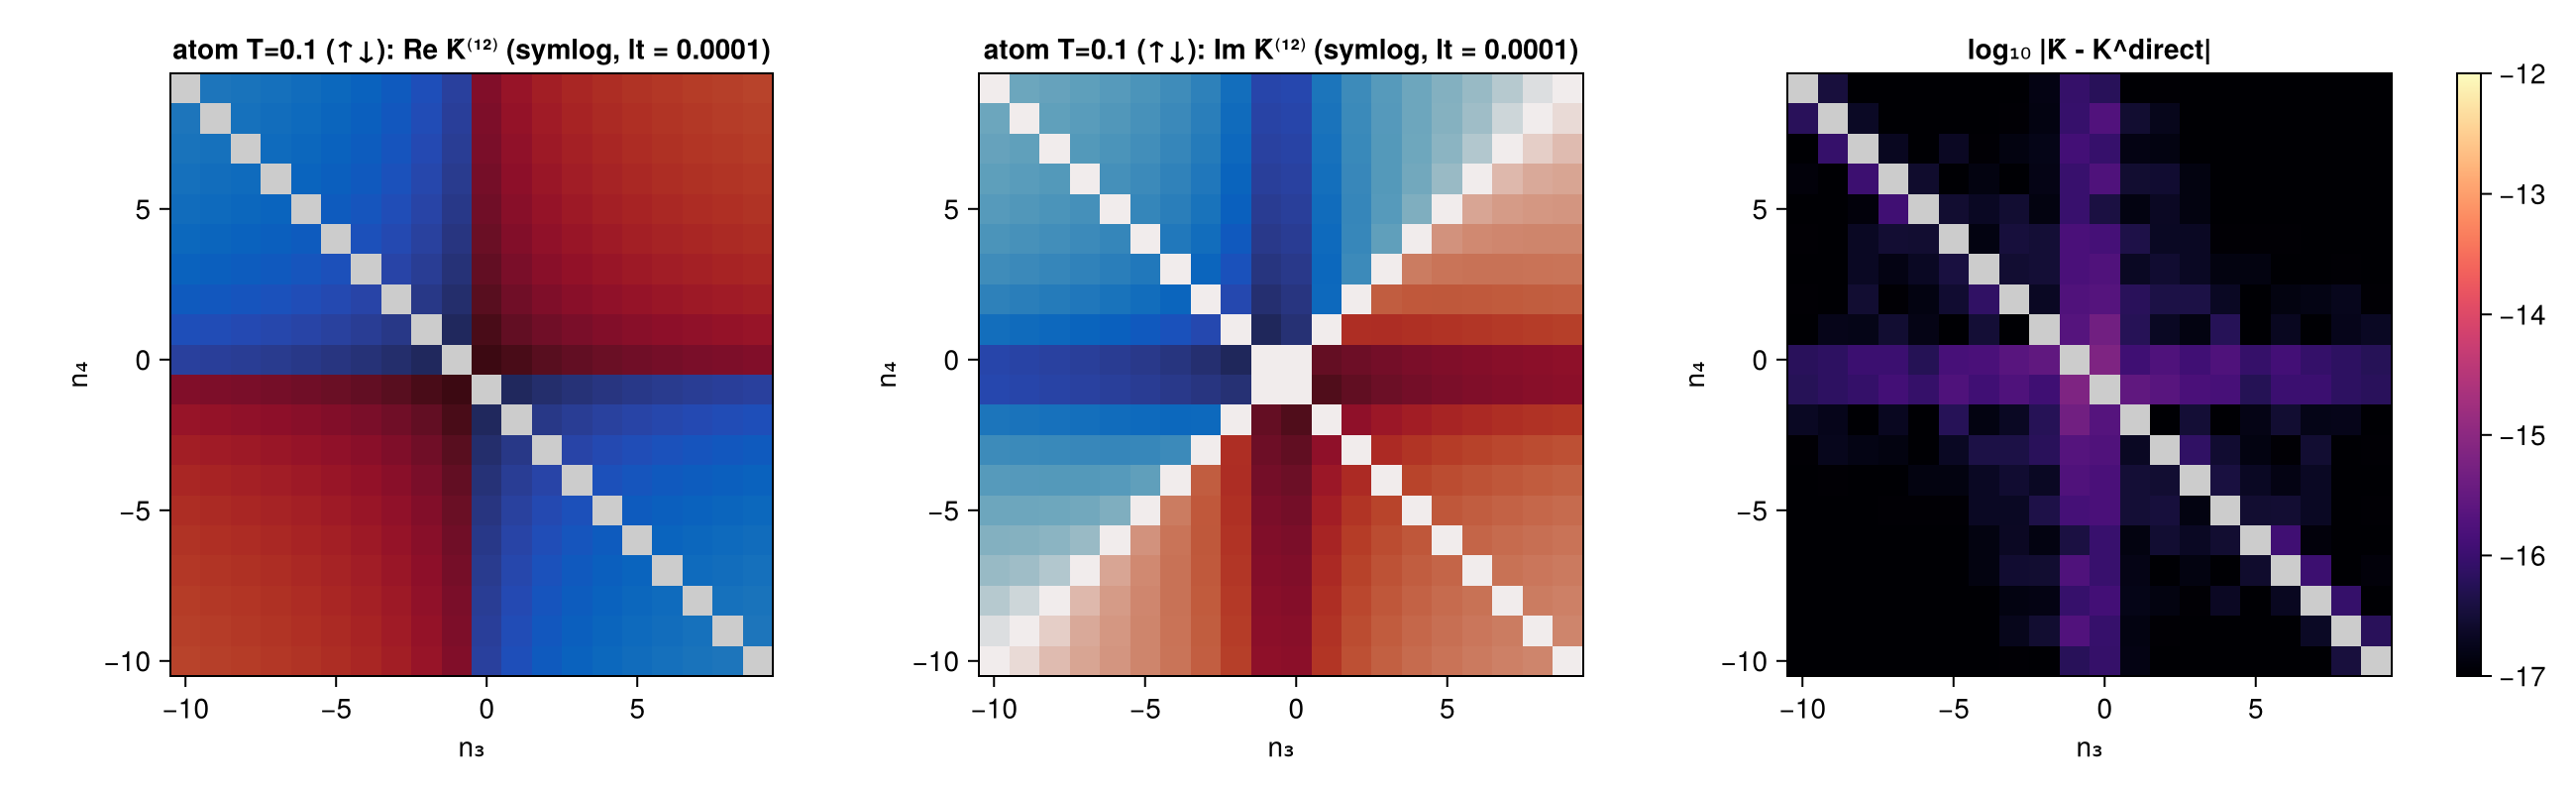

In [10]:
function symlog_heat!(ax, n3s, n4s, M; lt = 1e-4)
    heatmap!(ax, n3s, n4s, map(x -> isnan(x) ? NaN : HA.symlog(x, lt), M); colormap = :balance, colorrange = (-1, 1), nan_color = :gray80)
end
function K_heatmaps(box; title = "", lt = 1e-4)
    fig = Figure(size = (1300, 400))
    for (j, (M, ttl)) in enumerate(((real.(box.Kt), "Re K̃⁽¹²⁾"), (imag.(box.Kt), "Im K̃⁽¹²⁾")))
        ax = Axis(fig[1, j]; xlabel = "n₃", ylabel = "n₄", title = "$title: $ttl (symlog, lt = $lt)", aspect = 1)
        symlog_heat!(ax, box.n3s, box.n4s, M; lt = lt)
    end
    E = abs.(box.Kt - box.Kd)
    ax = Axis(fig[1, 3]; xlabel = "n₃", ylabel = "n₄", title = "log₁₀ |K̃ - K^direct|", aspect = 1)
    hm = heatmap!(ax, box.n3s, box.n4s, log10.(fl.(E)); colormap = :magma, colorrange = (-17, -12), nan_color = :gray80)
    Colorbar(fig[1, 4], hm)
    fig
end
savefig("atom_K_updn", K_heatmaps(R["V1 atom T=0.1 updn"][:checks][:box]; title = "atom T=0.1 (↑↓)"))

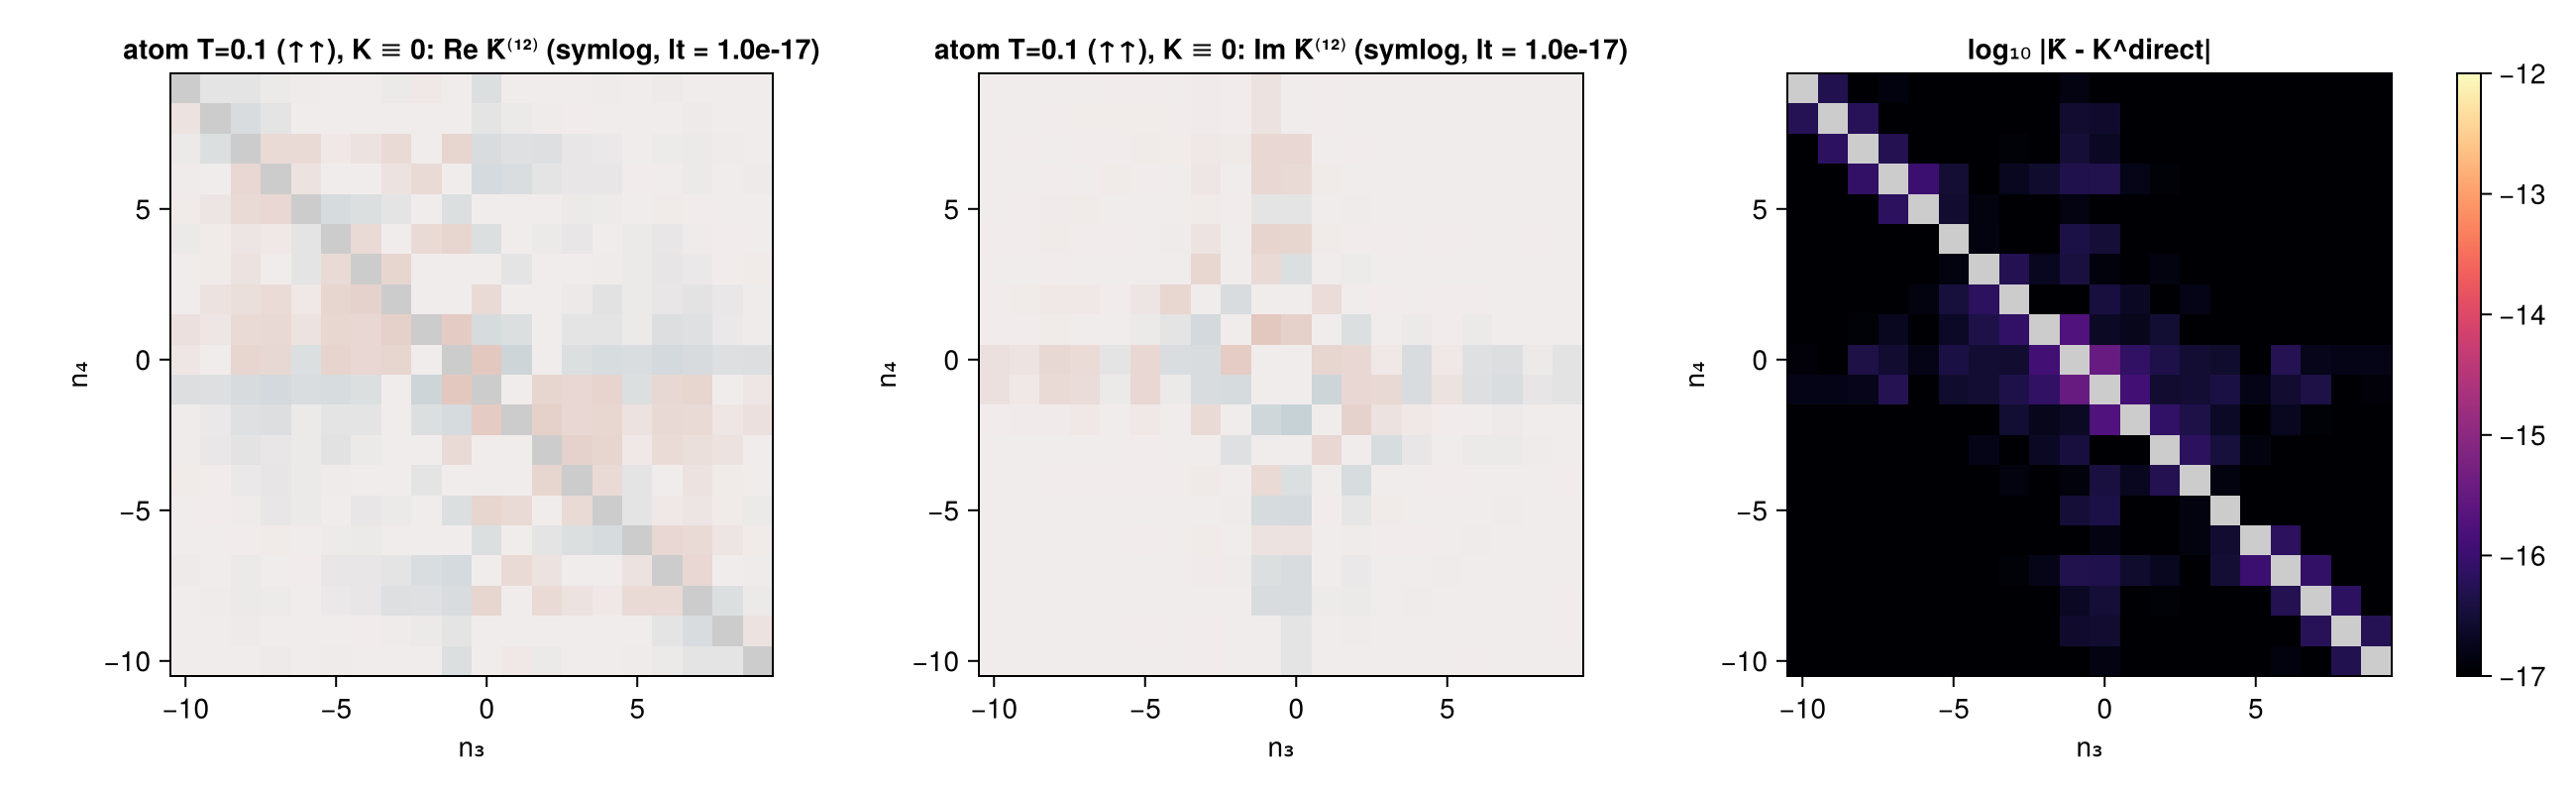

In [11]:
savefig("atom_K_upup", K_heatmaps(R["V1 atom T=0.1 upup"][:checks][:box]; title = "atom T=0.1 (↑↑), K ≡ 0", lt = 1e-17))

## 3. Wilson-chain ED (V2a, V2b)

`siam(U = 0.5, εd = -0.1, Δ = 0.1)`, chains with sites $-1..N_{\rm ch}$, $N_{\rm ch}\in\{1,2\}$ (64 and 256 states),
$T=0.05$, with and without field $B=0.05$, both channels. **V2a**: exact positions on an ExactGrid (`degtol = 1e-10`).
**V2b**: the same ED binned on `LogGrid(emin = 1e-5, emax = 10, ndec = 16)`. Expected (Theorem 2): C1, C5–C8
guaranteed for both; C3 (Dyson) and C4 (bath leakage) guaranteed only for exact data (they use the equation of motion,
which binned data violate by the bin width).

In [12]:
function chain_table(keys)
    @printf("%-34s %6s %5s %4s %4s %9s %9s %9s %9s %9s %9s %9s %9s %9s %9s\n", "case", "bins", "R", "L", "L_B", "C1", "C2", "C3", "C4",
            "C4 unst", "C5", "C6", "C7", "C8", "t [s]")
    for k in keys
        o = R[k]; c = o[:checks]
        @printf("%-34s %6d %5d %4d %4d %9.1e %9.1e %9.1e %9.1e %9s %9.1e %9.1e %9.1e %9.1e %9.1f\n", k, c[:nbins], c[:R], c[:L], c[:LB],
                c[:C1], c[:C2], c[:C3], c[:C4], haskey(o, :unstab) ? @sprintf("%.1e", o[:unstab].C4) : "—", c[:C5], c[:C6], c[:C7], c[:C8],
                sum(values(o[:timings])))
    end
end
println("V2a (ExactGrid):"); chain_table(["V2 Nch=$N B=$f $c exact" for N in (1, 2) for f in (0.0, 0.05) for c in (:updn, :upup)])
println("\nV2b (LogGrid):");  chain_table(["V2 Nch=$N B=$f $c log" for N in (1, 2) for f in (0.0, 0.05) for c in (:updn, :upup)])
println("\nsanity (Sec. 3.3), max over V2 cases: ")
for gk in (:exact, :log)
    S = [R["V2 Nch=$N B=$f $c $gk"][:checks][:sanity] for N in (1, 2) for f in (0.0, 0.05) for c in (:updn, :upup)]
    @printf("  %-5s herm %.1e, min eig/max‖W‖ %.1e, sum rule %.1e, 3p totals %.1e, C5 %.1e, Boltzmann-shortcut diff %.1e\n", gk,
            maximum(s.herm_err for s in S), minimum(s.min_eig_rel for s in S), maximum(s.sumrule_err for s in S),
            maximum(s.totals3_err for s in S), maximum(s.C5 for s in S), maximum(s.boltzmann_diff for s in S))
end
println("clamped positions on the LogGrid: ", sum(R["V2 Nch=$N B=$f $c log"][:data].meta[:nclamped] for N in (1, 2) for f in (0.0, 0.05) for c in (:updn, :upup)))

V2a (ExactGrid):


case                                 bins     R    L  L_B        C1        C2        C3        C4   C4 unst        C5        C6        C7        C8     t [s]
V2 Nch=1 B=0.0 updn exact             625   207  203  217   2.9e-15   1.2e-13   4.4e-14   1.2e-14   8.4e-01   0.0e+00   7.5e-16   9.8e-16   4.7e-15      16.7


V2 Nch=1 B=0.0 upup exact             625   207  203  217   3.2e-15   1.1e-13   4.4e-14   1.2e-14   8.3e-01   0.0e+00   7.7e-16   8.1e-16   4.1e-14      12.9
V2 Nch=1 B=0.05 updn exact            871   282  279  307   2.2e-15   1.5e-13   6.5e-14   5.0e-16   4.7e-01   0.0e+00   1.2e-15   8.7e-16   3.2e-15      27.1
V2 Nch=1 B=0.05 upup exact            871   282  279  307   1.3e-15   1.5e-13   6.5e-14   5.0e-16   5.5e-01   0.0e+00   9.7e-16   8.4e-16   2.4e-14      27.1
V2 Nch=2 B=0.0 updn exact            7901  2616 2612 2797   4.4e-15   1.6e-13   1.0e-13   4.9e-15   2.5e-01   0.0e+00   2.7e-15   9.7e-16   4.8e-14     528.6
V2 Nch=2 B=0.0 upup exact            7901  2616 2612 2797   4.7e-15   1.2e-12   1.0e-13   4.9e-15   2.4e-01   0.0e+00   2.4e-15   5.0e-16   2.8e-13     537.2
V2 Nch=2 B=0.05 updn exact          12163  3840 3836 4483   6.7e-15   2.4e-13   1.6e-13   5.6e-15   2.0e-01   0.0e+00   5.4e-15   5.6e-16   8.2e-14    1507.7
V2 Nch=2 B=0.05 upup exact          12163  3840 3836

clamped positions on the LogGrid: 0

In [13]:
# N = 2 block test on the chain with field B = 0.05 (Nch = 1, ExactGrid)
o2 = R["V2 block N=2"]; ou = R["V2 block up"]; od = R["V2 block dn"]
b2 = o2[:checks][:box]; bu = ou[:checks][:box]; bd = od[:checks][:box]
m_ = .!isnan.(real.(bu.Kd))
zs = HA.vk_testpoints(o2[:data])
dΣ = maximum(z -> maximum(abs, HA.sigma_chain(o2[:res].ch, z) - Diagonal([HA.sigma_chain(ou[:res].ch, z)[1], HA.sigma_chain(od[:res].ch, z)[1]])), zs)
@printf("chain N=2 block (field 0.05): |ΔK̃↑↑| = %.1e, |ΔK̃↓↓| = %.1e, |K̃ off| = %.1e, |ΔΣ^S| = %.1e; L(N=2) = %d blocks, L(↑) = %d, L(↓) = %d\n",
        maximum(abs, b2.Kt[1, 1, :, :][m_] - bu.Kt[m_]), maximum(abs, b2.Kt[2, 2, :, :][m_] - bd.Kt[m_]),
        max(maximum(abs, b2.Kt[1, 2, :, :][m_]), maximum(abs, b2.Kt[2, 1, :, :][m_])), dΣ,
        o2[:checks][:L], ou[:checks][:L], od[:checks][:L])
println("spin blocks differ with field: |K̃↑↑ - K̃↓↓| = ", @sprintf("%.2e", maximum(abs, bu.Kt[m_] - bd.Kt[m_])))

chain N=2 block (field 0.05): |ΔK̃↑↑| = 1.2e-16, |ΔK̃↓↓| = 3.3e-16, |K̃ off| = 1.0e-16, |ΔΣ^S| = 2.8e-16; L(N=2) = 279 blocks, L(↑) = 279, L(↓) = 279
spin blocks differ with field: |K̃↑↑ - K̃↓↓| = 

2.36e-01


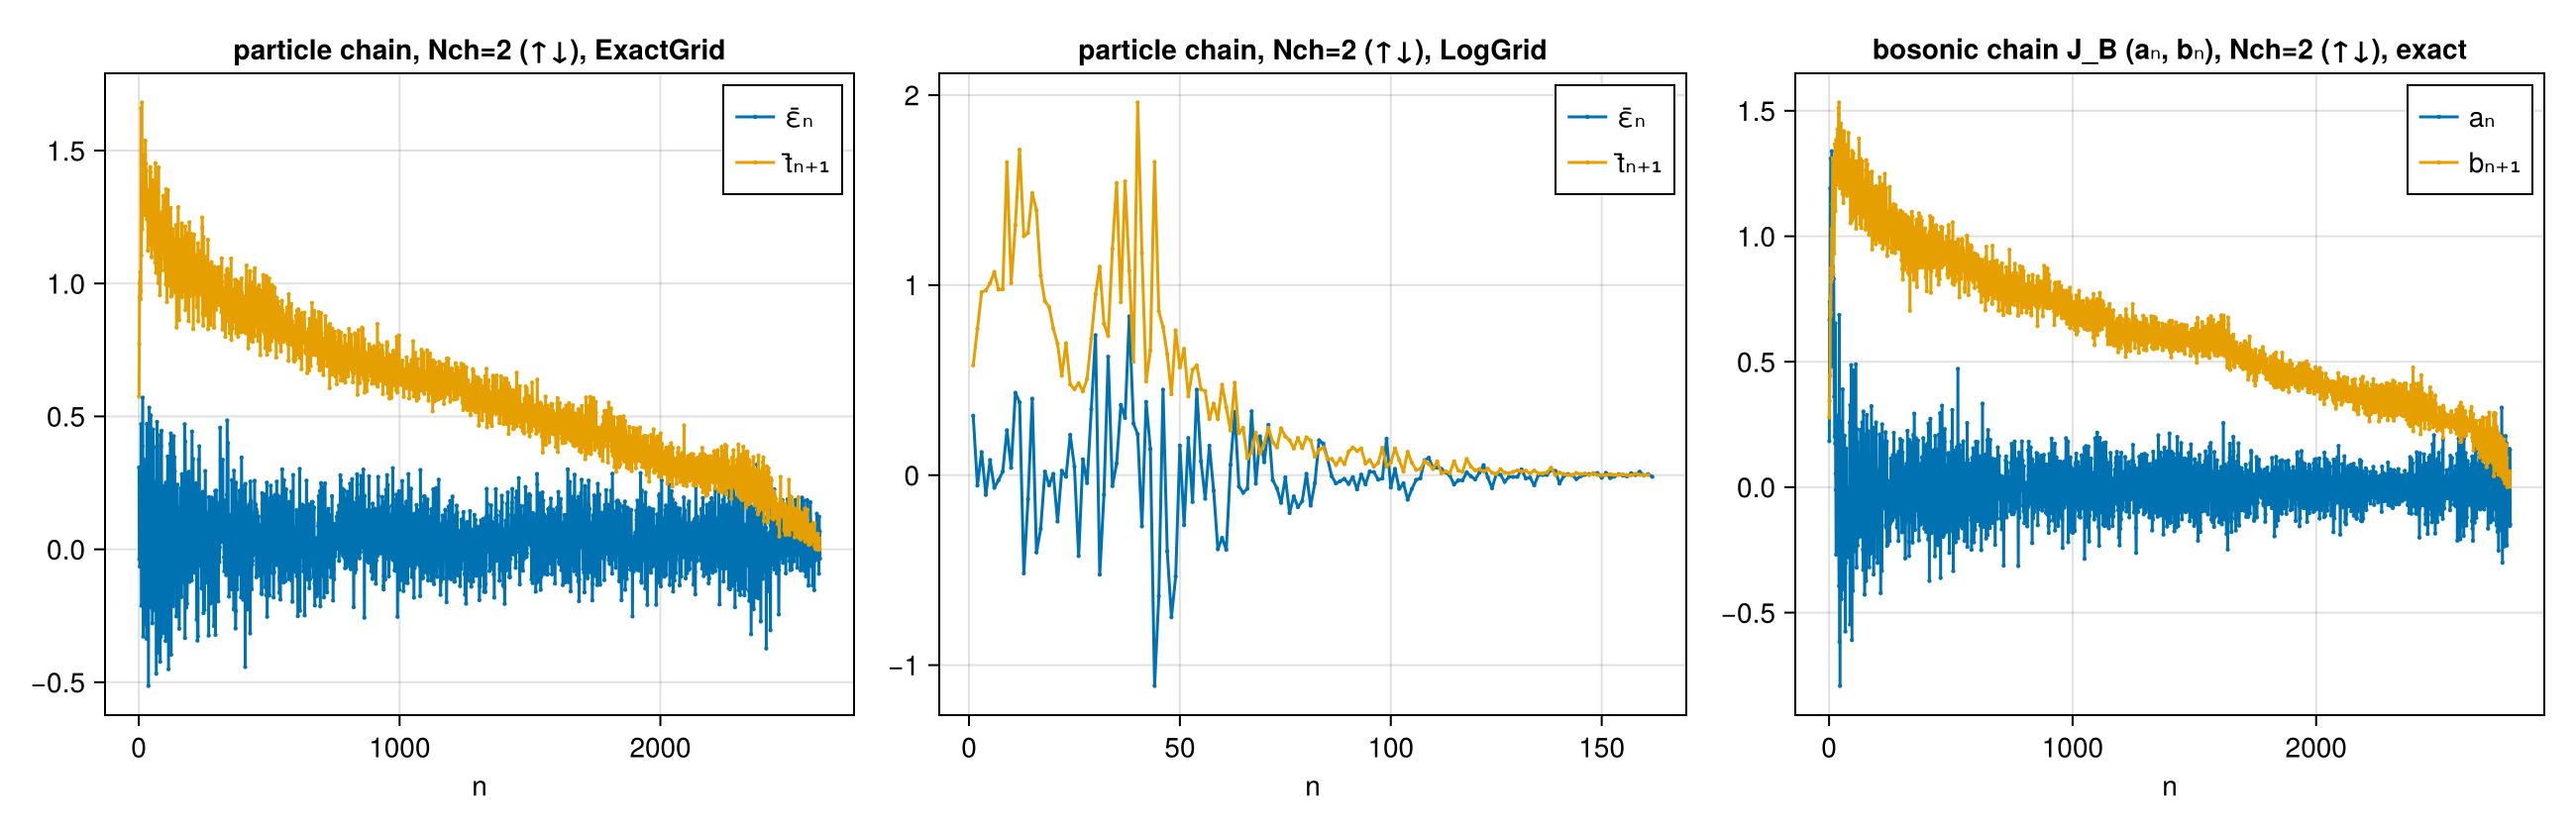

In [14]:
# chain coefficients
fig = Figure(size = (1300, 420))
for (j, gk) in enumerate((:exact, :log))
    o = R["V2 Nch=2 B=0.0 updn $gk"]; ch = o[:res].ch
    ax = Axis(fig[1, j]; xlabel = "n", title = "particle chain, Nch=2 (↑↓), $(gk === :exact ? "ExactGrid" : "LogGrid")")
    scatterlines!(ax, 1:HA.nblocks(ch.Jbar), [real(e[1]) for e in ch.Jbar.eps]; markersize = 3, label = "ε̄ₙ")
    scatterlines!(ax, 1:(HA.nblocks(ch.Jbar) - 1), [real(t[1]) for t in ch.Jbar.lower]; markersize = 3, label = "t̄ₙ₊₁")
    axislegend(ax; position = :rt)
end
o = R["V2 Nch=2 B=0.0 updn exact"]; ch = o[:res].ch
ax = Axis(fig[1, 3]; xlabel = "n", title = "bosonic chain J_B (aₙ, bₙ), Nch=2 (↑↓), exact")
scatterlines!(ax, 1:HA.nblocks(ch.JB), [e[1] for e in ch.JB.eps]; markersize = 3, label = "aₙ")
scatterlines!(ax, 1:(HA.nblocks(ch.JB) - 1), [t[1] for t in ch.JB.lower]; markersize = 3, label = "bₙ₊₁")
axislegend(ax; position = :rt)
savefig("chain_coefficients", fig)

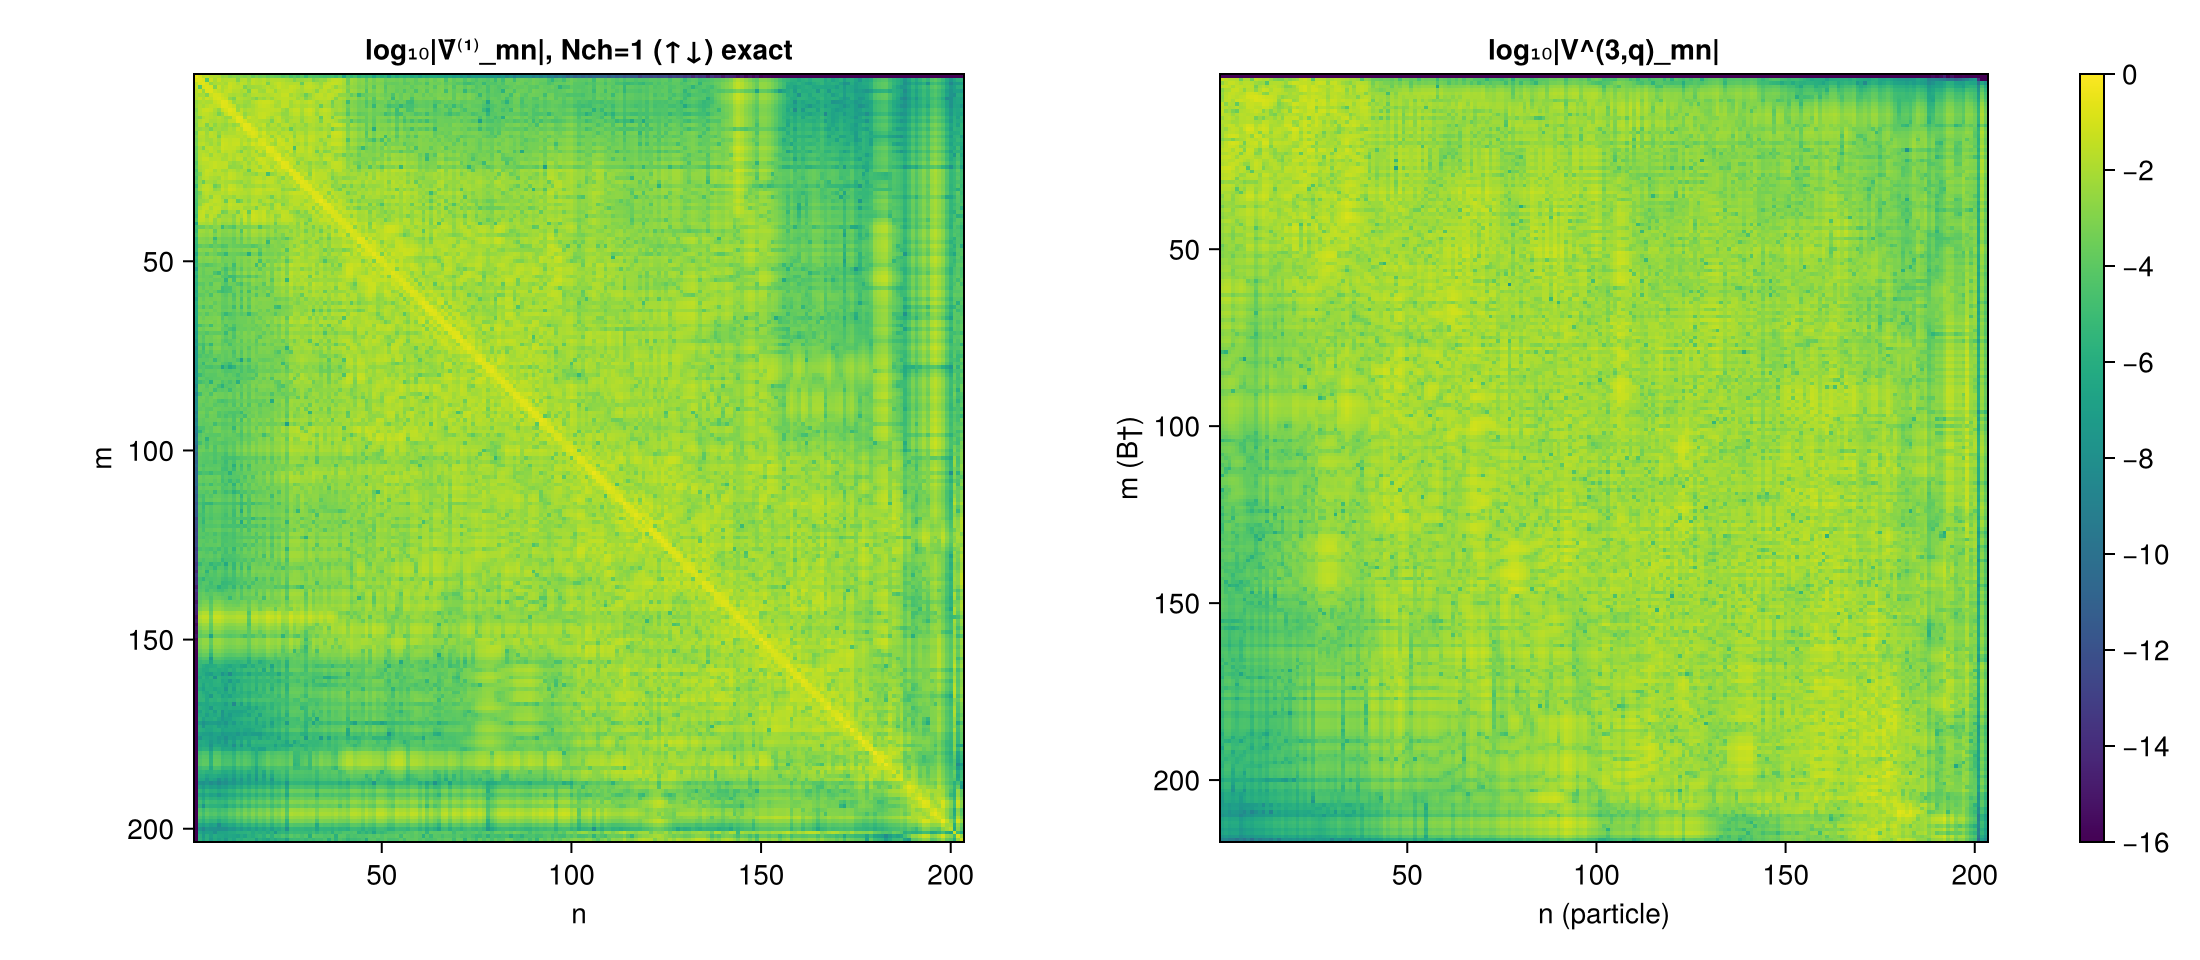

In [15]:
# couplings |V̄⁽¹⁾_mn| and |V^(3,q)_mn|
fig = Figure(size = (1100, 480))
o = R["V2 Nch=1 B=0.0 updn exact"]; cp = o[:res].cp
ax = Axis(fig[1, 1]; xlabel = "n", ylabel = "m", title = "log₁₀|V̄⁽¹⁾_mn|, Nch=1 (↑↓) exact", aspect = 1, yreversed = true)
hm = heatmap!(ax, permutedims(log10.(fl.(abs.(cp.V1)))); colormap = :viridis, colorrange = (-16, 0))
ax = Axis(fig[1, 2]; xlabel = "n (particle)", ylabel = "m (B†)", title = "log₁₀|V^(3,q)_mn|", aspect = 1, yreversed = true)
heatmap!(ax, permutedims(log10.(fl.(abs.(cp.V3[:q][1])))); colormap = :viridis, colorrange = (-16, 0))
Colorbar(fig[1, 3], hm)
savefig("couplings", fig)

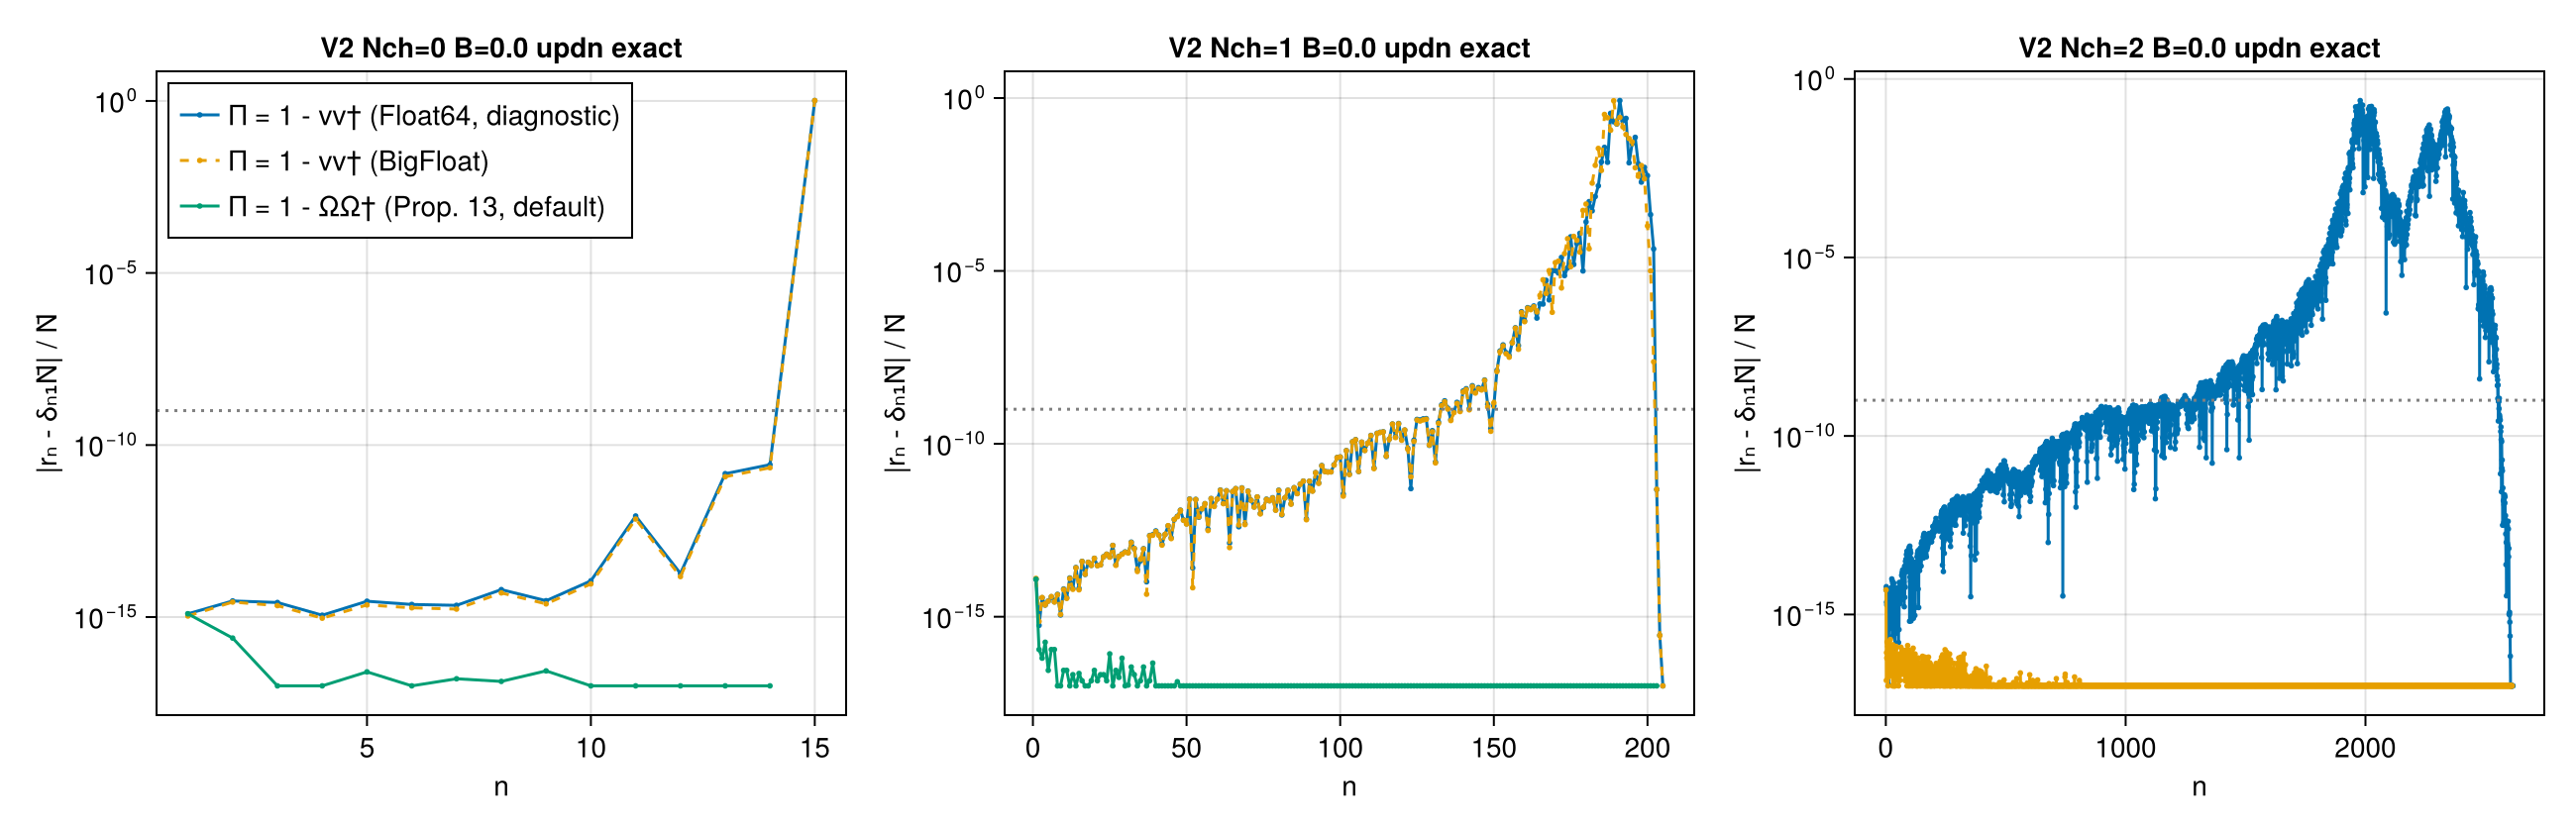

In [16]:
# bath leakage |r_n - δ_n1 N̄| / N̄: the default (stabilized, Prop. 13) chain and the unstabilized diagnostic
fig = Figure(size = (1300, 420))
for (j, k) in enumerate(("V2 Nch=0 B=0.0 updn exact", "V2 Nch=1 B=0.0 updn exact", "V2 Nch=2 B=0.0 updn exact"))
    o = R[k]
    ax = Axis(fig[1, j]; yscale = log10, xlabel = "n", ylabel = "|rₙ - δₙ₁N̄| / N̄", title = k)
    pu = o[:unstab].profile
    scatterlines!(ax, eachindex(pu), fl.(pu); markersize = 4, label = "Π = 1 - vv† (Float64, diagnostic)")
    haskey(o, :big_unstab) && scatterlines!(ax, eachindex(o[:big_unstab].profile), fl.(o[:big_unstab].profile); markersize = 4, linestyle = :dash, label = "Π = 1 - vv† (BigFloat)")
    p = haskey(o, :chain) ? o[:chain].profile : HA.leakage_profile(o[:res].ch)
    scatterlines!(ax, eachindex(p), fl.(p); markersize = 4, label = "Π = 1 - ΩΩ† (Prop. 13, default)")
    hlines!(ax, [1e-9]; color = :gray, linestyle = :dot)
    j == 1 && axislegend(ax; position = :lt)
end
savefig("bath_leakage", fig)

In [17]:
for k in ("V2 Nch=0 B=0.0 updn exact", "V2 Nch=1 B=0.0 updn exact", "V2 Nch=1 B=0.0 upup exact", "V2 Nch=2 B=0.0 updn exact", "V2 Nch=2 B=0.05 upup exact")
    o = R[k]; u = o[:unstab]; c = o[:checks]
    @printf("%-28s R=%5d  L=%4d (unstab %4d, BigFloat unstab %s)  C4 = %.1e (unstab %.2e, BigFloat unstab %s)  dim Ω = %d  ‖Ω†Ū‖ = %.1e  ΔΣ^S = %.1e  ΔK̃ = %.1e\n",
            k, c[:R], c[:L], u.L, haskey(o, :big_unstab) ? string(o[:big_unstab].L) : "—", c[:C4], u.C4,
            haskey(o, :big_unstab) ? @sprintf("%.2e", o[:big_unstab].C4) : "—", c[:Omega_dim], c[:Omega_overlap], u.dSigma, u.dK)
end

V2 Nch=0 B=0.0 updn exact    R=   16  L=  14 (unstab   15, BigFloat unstab 15)  C4 = 1.2e-15 (unstab 1.03e+00, BigFloat unstab 1.03e+00)  dim Ω = 2  ‖Ω†Ū‖ = 1.3e-15  ΔΣ^S = 3.1e-16  ΔK̃ = 1.0e-15
V2 Nch=1 B=0.0 updn exact    R=  207  L= 203 (unstab  205, BigFloat unstab 205)  C4 = 1.2e-14 (unstab 8.45e-01, BigFloat unstab 8.35e-01)  dim Ω = 3  ‖Ω†Ū‖ = 1.3e-14  ΔΣ^S = 2.8e-16  ΔK̃ = 1.7e-15


V2 Nch=1 B=0.0 upup exact    R=  207  L= 203 (unstab  205, BigFloat unstab 205)  C4 = 1.2e-14 (unstab 8.30e-01, BigFloat unstab 8.14e-01)  dim Ω = 3  ‖Ω†Ū‖ = 1.3e-14  ΔΣ^S = 3.5e-16  ΔK̃ = 1.4e-14
V2 Nch=2 B=0.0 updn exact    R= 2616  L=2612 (unstab 2615, BigFloat unstab —)  C4 = 4.9e-15 (unstab 2.48e-01, BigFloat unstab —)  dim Ω = 4  ‖Ω†Ū‖ = 1.0e-14  ΔΣ^S = 3.1e-16  ΔK̃ = 1.7e-15
V2 Nch=2 B=0.05 upup exact   R= 3840  L=3836 (unstab 3839, BigFloat unstab —)  C4 = 5.6e-15 (unstab 2.01e-01, BigFloat unstab —)  dim Ω = 4  ‖Ω†Ū‖ = 1.3e-14  ΔΣ^S = 2.5e-16  ΔK̃ = 6.0e-15


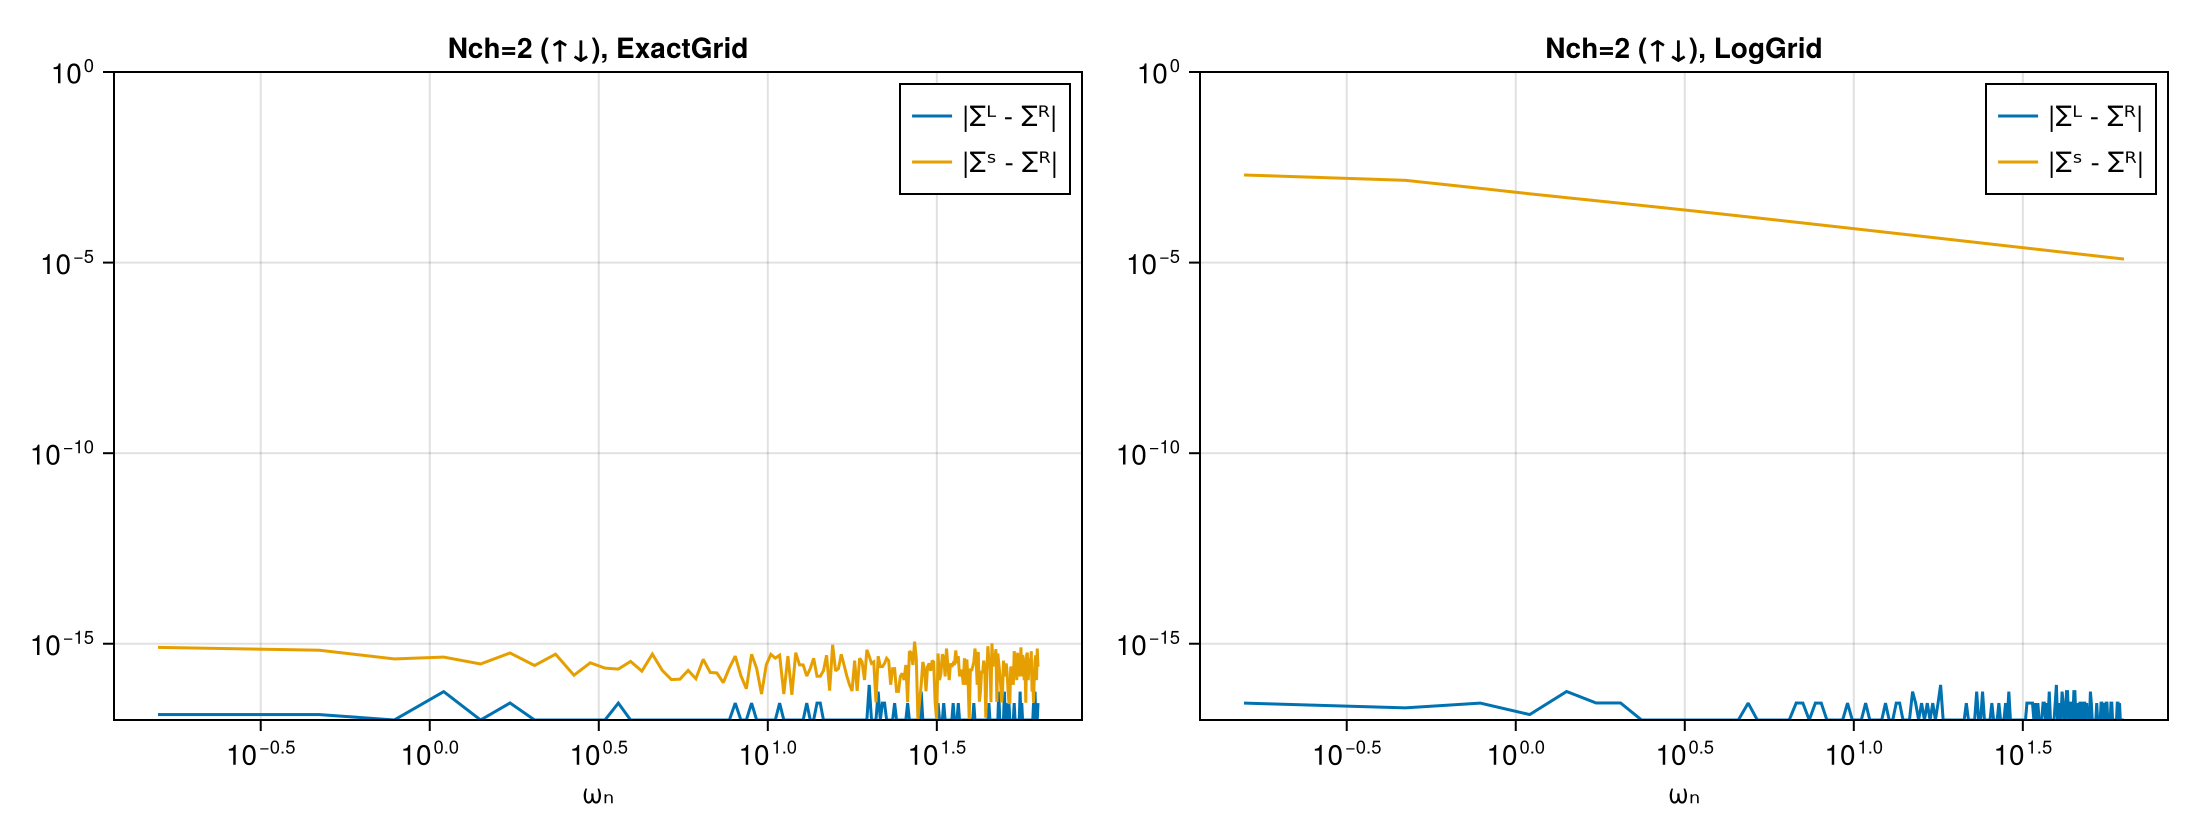

In [18]:
# |Σ^L - Σ^R| and |Σ^S - Σ^R| on the Matsubara axis, exact vs binned (why Lemma 9 is needed)
fig = Figure(size = (1100, 420))
for (j, gk) in enumerate((:exact, :log))
    o = R["V2 Nch=2 B=0.0 updn $gk"]; d = o[:data]; ch = o[:res].ch
    ns = 0:200
    LR = Float64[]; SR = Float64[]
    for n in ns
        ΣR, ΣL, ΣS = HA.sigmas(d, ch, im * HA.vk_fermionic(n, d.T))
        push!(LR, abs(ΣL[1] - ΣR[1])); push!(SR, abs(ΣS[1] - ΣR[1]))
    end
    ax = Axis(fig[1, j]; yscale = log10, xscale = log10, xlabel = "ωₙ", title = "Nch=2 (↑↓), $(gk === :exact ? "ExactGrid" : "LogGrid")")
    ωs = [HA.vk_fermionic(n, d.T) for n in ns]
    lines!(ax, ωs, fl.(LR); label = "|Σᴸ - Σᴿ|")
    lines!(ax, ωs, fl.(SR); label = "|Σˢ - Σᴿ|")
    ylims!(ax, 1e-17, 1)
    axislegend(ax; position = :rt)
end
savefig("sigma_estimators", fig)

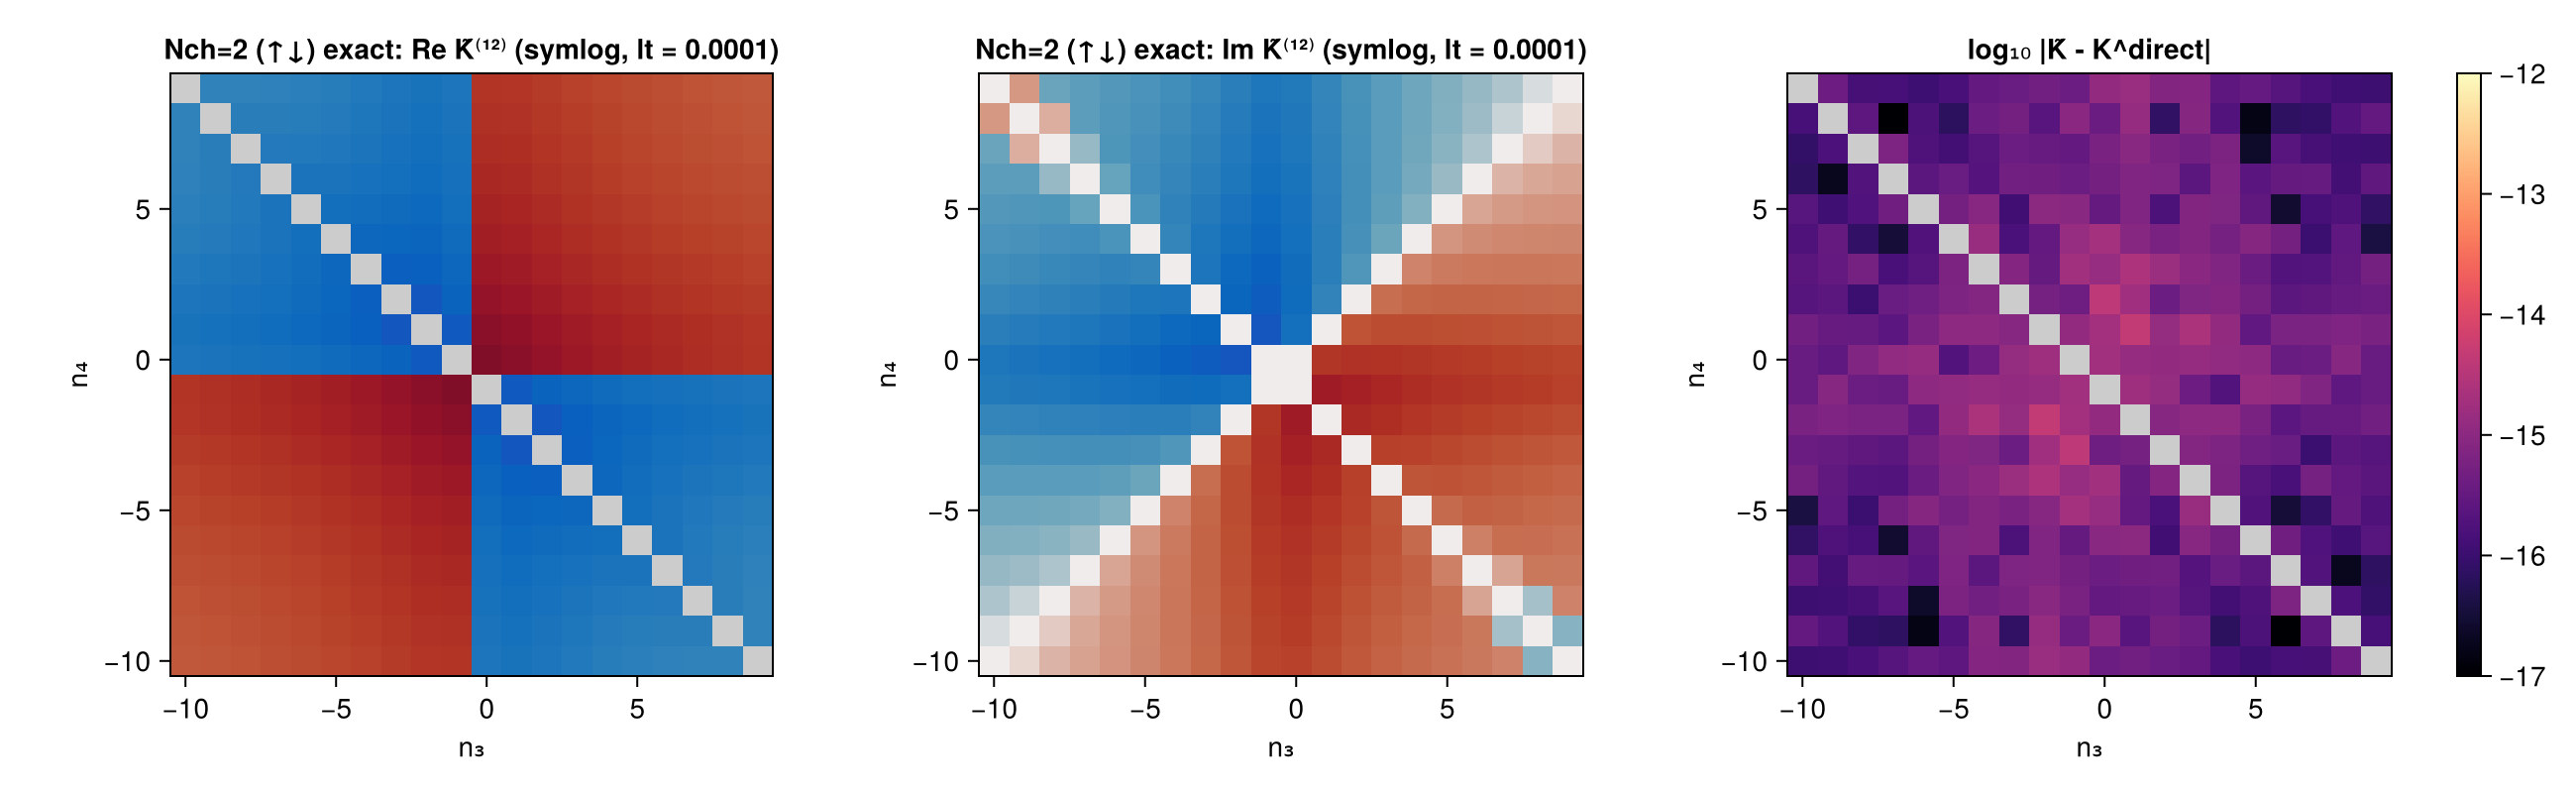

In [19]:
savefig("chain_K_exact", K_heatmaps(R["V2 Nch=2 B=0.0 updn exact"][:checks][:box]; title = "Nch=2 (↑↓) exact"))

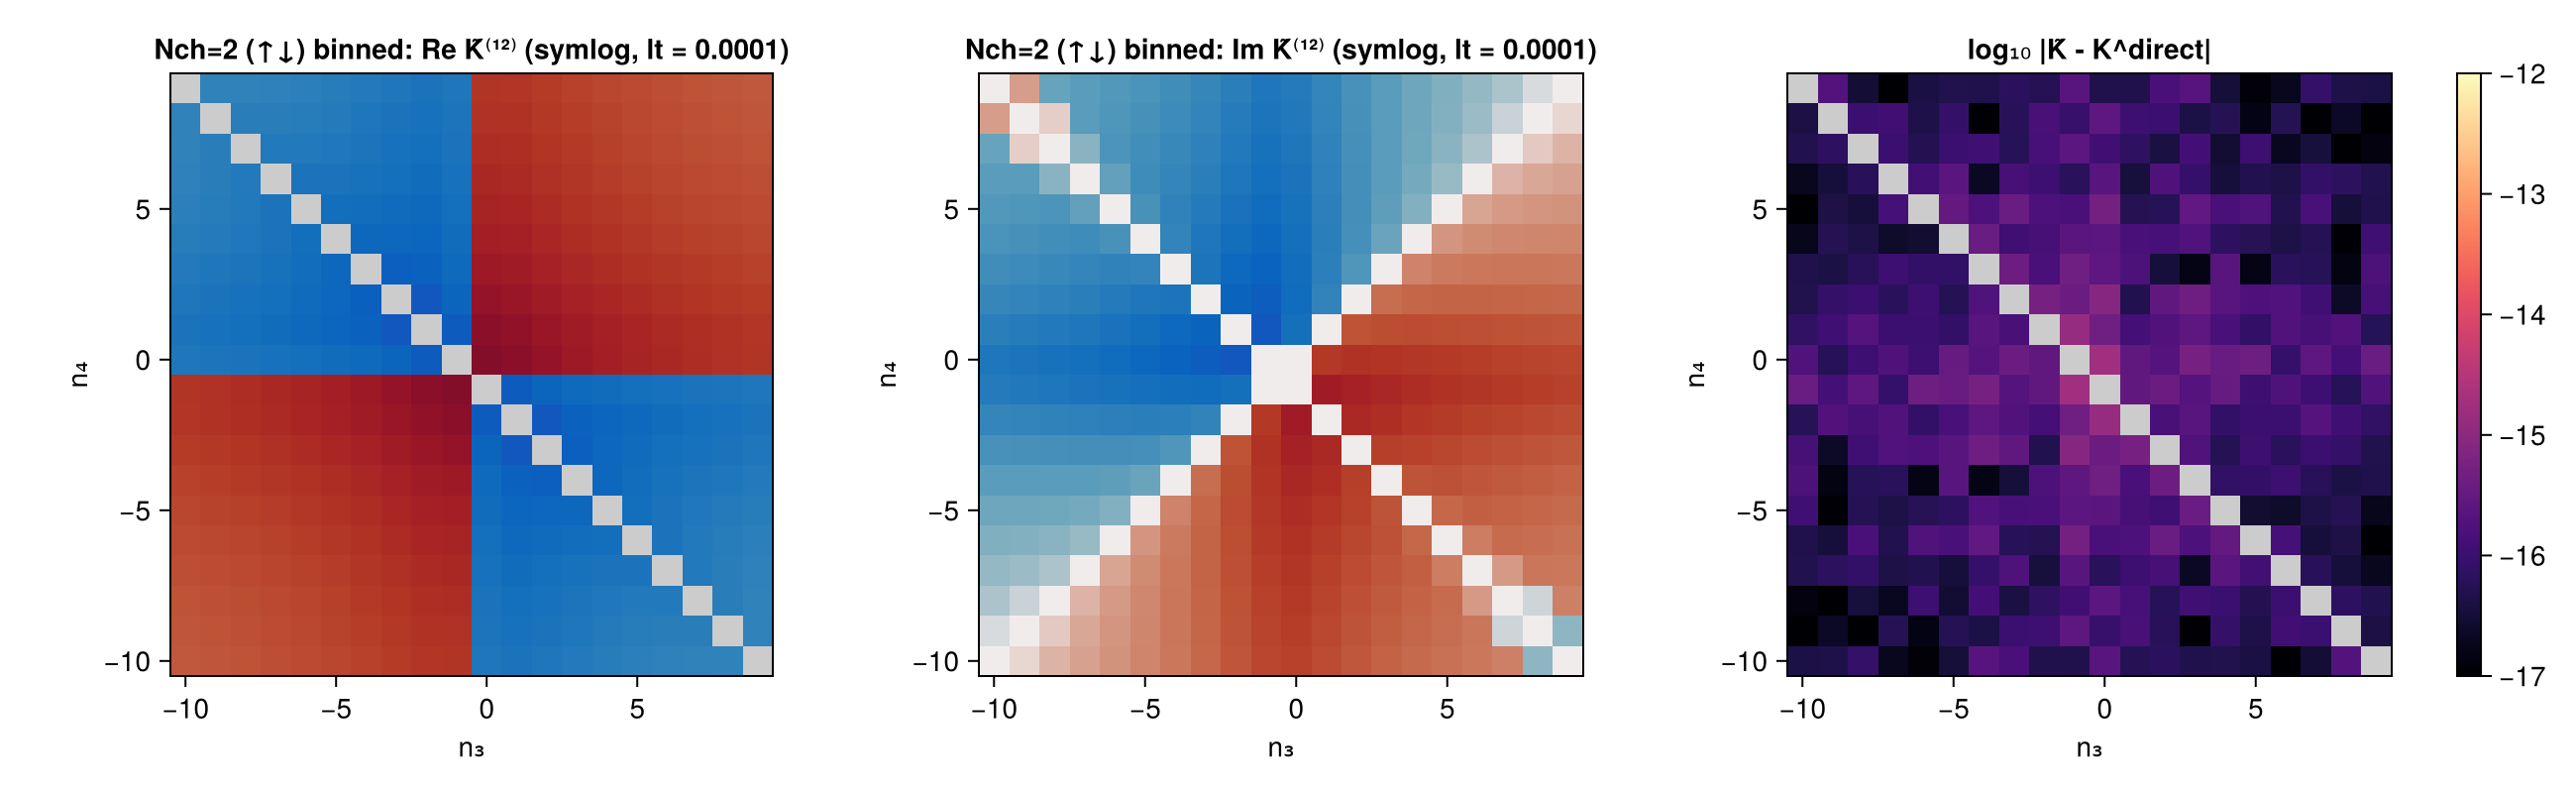

In [20]:
savefig("chain_K_binned", K_heatmaps(R["V2 Nch=2 B=0.0 updn log"][:checks][:box]; title = "Nch=2 (↑↓) binned"))

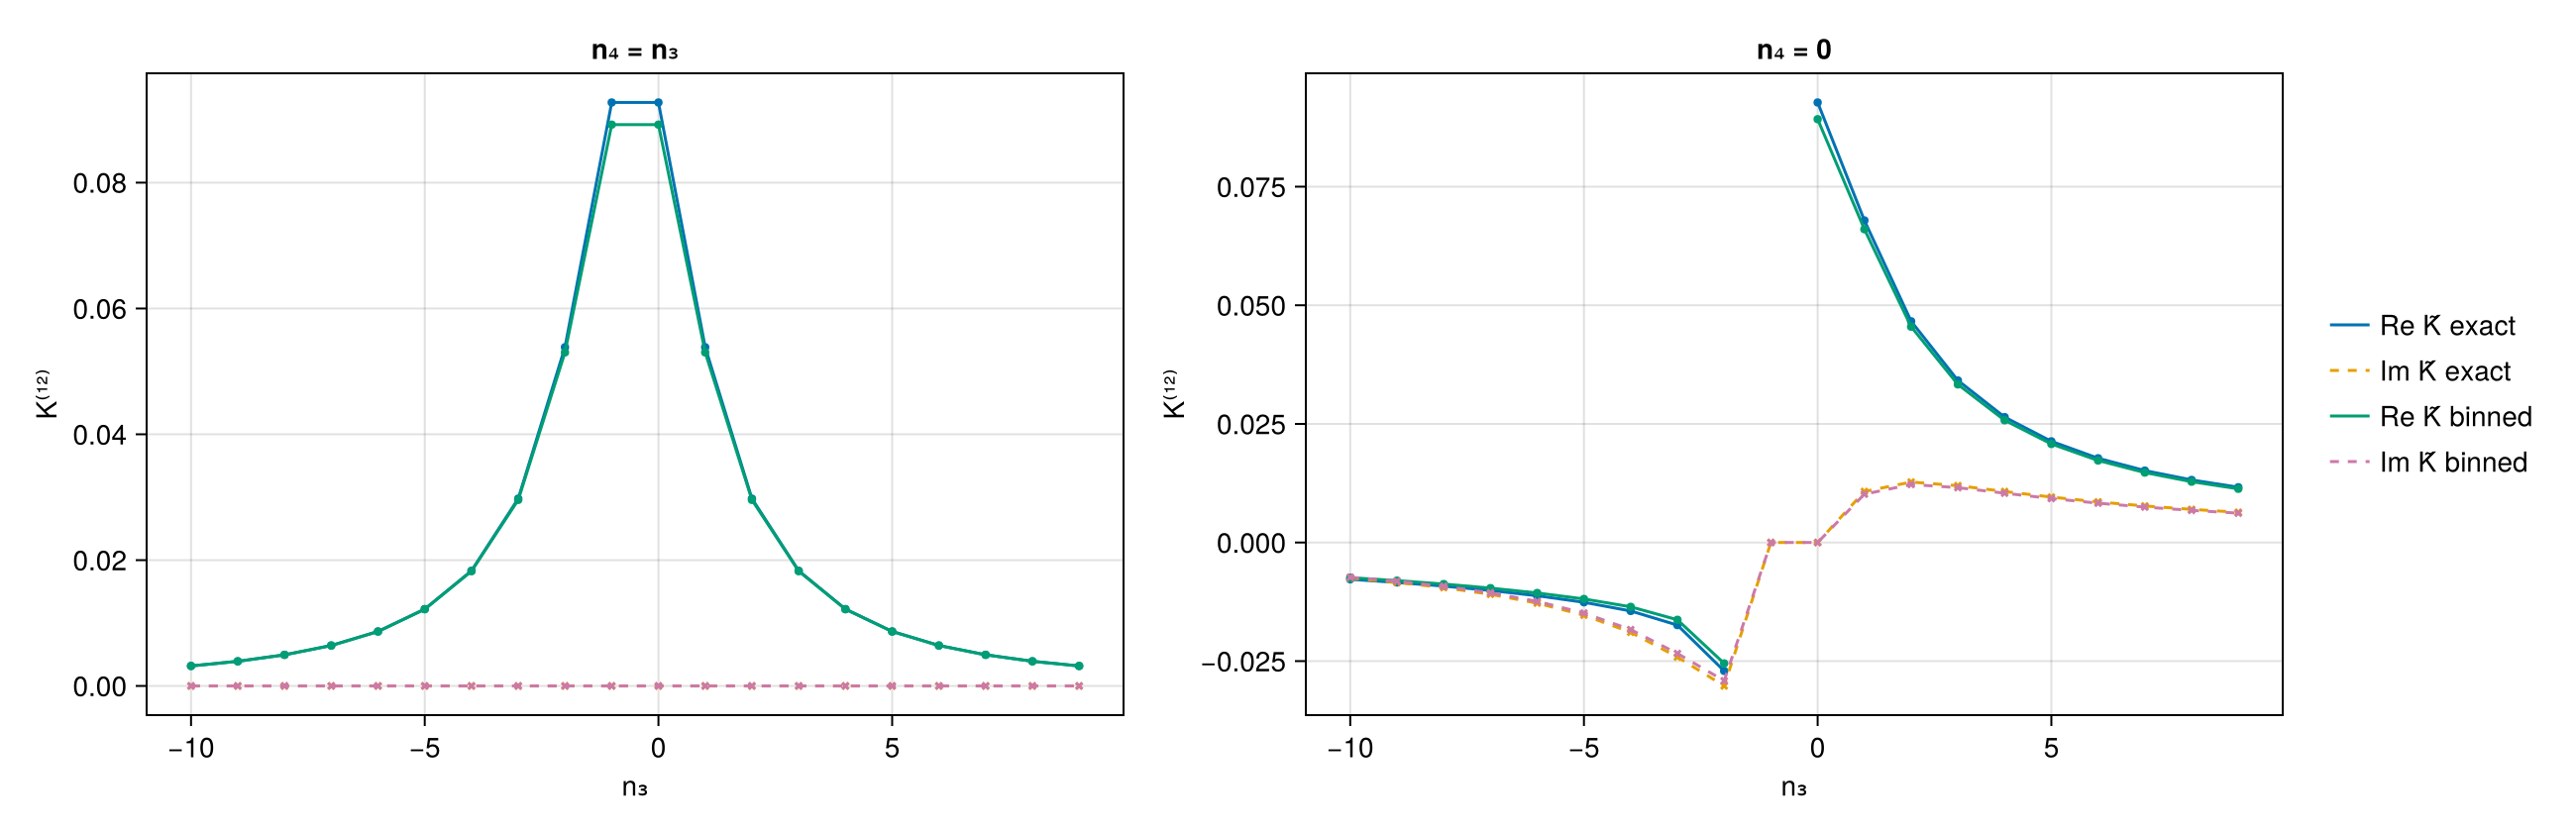

In [21]:
# two frequency slices of K̃ vs K^direct
function K_slices(keys; labels = keys)
    fig = Figure(size = (1300, 420))
    for (j, (sl, ttl)) in enumerate(((:diag, "n₄ = n₃"), (:fix, "n₄ = 0")))
        ax = Axis(fig[1, j]; xlabel = "n₃", ylabel = "K⁽¹²⁾", title = ttl)
        for (k, lb) in zip(keys, labels)
            bx = R[k][:checks][:box]
            idx = sl === :diag ? [(i, i) for i in eachindex(bx.n3s)] : [(i, findfirst(==(0), bx.n4s)) for i in eachindex(bx.n3s)]
            lines!(ax, bx.n3s, [real(bx.Kt[i...]) for i in idx]; label = "Re K̃ $lb")
            scatter!(ax, bx.n3s, [real(bx.Kd[i...]) for i in idx]; markersize = 6, marker = :circle)
            lines!(ax, bx.n3s, [imag(bx.Kt[i...]) for i in idx]; linestyle = :dash, label = "Im K̃ $lb")
            scatter!(ax, bx.n3s, [imag(bx.Kd[i...]) for i in idx]; markersize = 6, marker = :xcross)
        end
        j == 2 && Legend(fig[1, 3], ax; framevisible = false)
    end
    fig
end
savefig("chain_K_slices", K_slices(["V2 Nch=2 B=0.0 updn exact", "V2 Nch=2 B=0.0 updn log"]; labels = ["exact", "binned"]))

case                                S-N̄²        Ū₁   spectra   weights       Σ^S   L_zac       L n_agree
V2 Nch=1 B=0.0 updn exact        8.0e-16   8.3e-16   3.2e-15   1.2e-13   3.3e-14     199     203      91


V2 Nch=1 B=0.0 updn log          1.1e-16   2.8e-16   4.5e-15   5.7e-14   2.2e-14      84      86      28
V2 Nch=1 B=0.0 upup exact        8.0e-16   8.3e-16   2.9e-15   1.1e-13   3.5e-14     201     203      91
V2 Nch=1 B=0.0 upup log          1.1e-16   2.8e-16   4.5e-15   5.7e-14   2.2e-14      84      86      28
V2 Nch=2 B=0.0 updn exact        3.5e-16   1.4e-16   5.6e-15   1.6e-13   5.8e-14    2551    2612     209
V2 Nch=2 B=0.0 updn log          1.2e-16   3.6e-16   3.6e-15   2.6e-14   9.1e-15     162     162      33
V2 Nch=2 B=0.0 upup exact        3.5e-16   1.4e-16   1.6e-14   1.2e-12   4.6e-13    2544    2612     210
V2 Nch=2 B=0.0 upup log          1.2e-16   3.6e-16   3.6e-15   2.6e-14   9.1e-15     162     162      33
V1 atom T=0.1 updn               1.1e-16   3.3e-16   4.0e-16   2.8e-14   1.2e-15       1       1       1


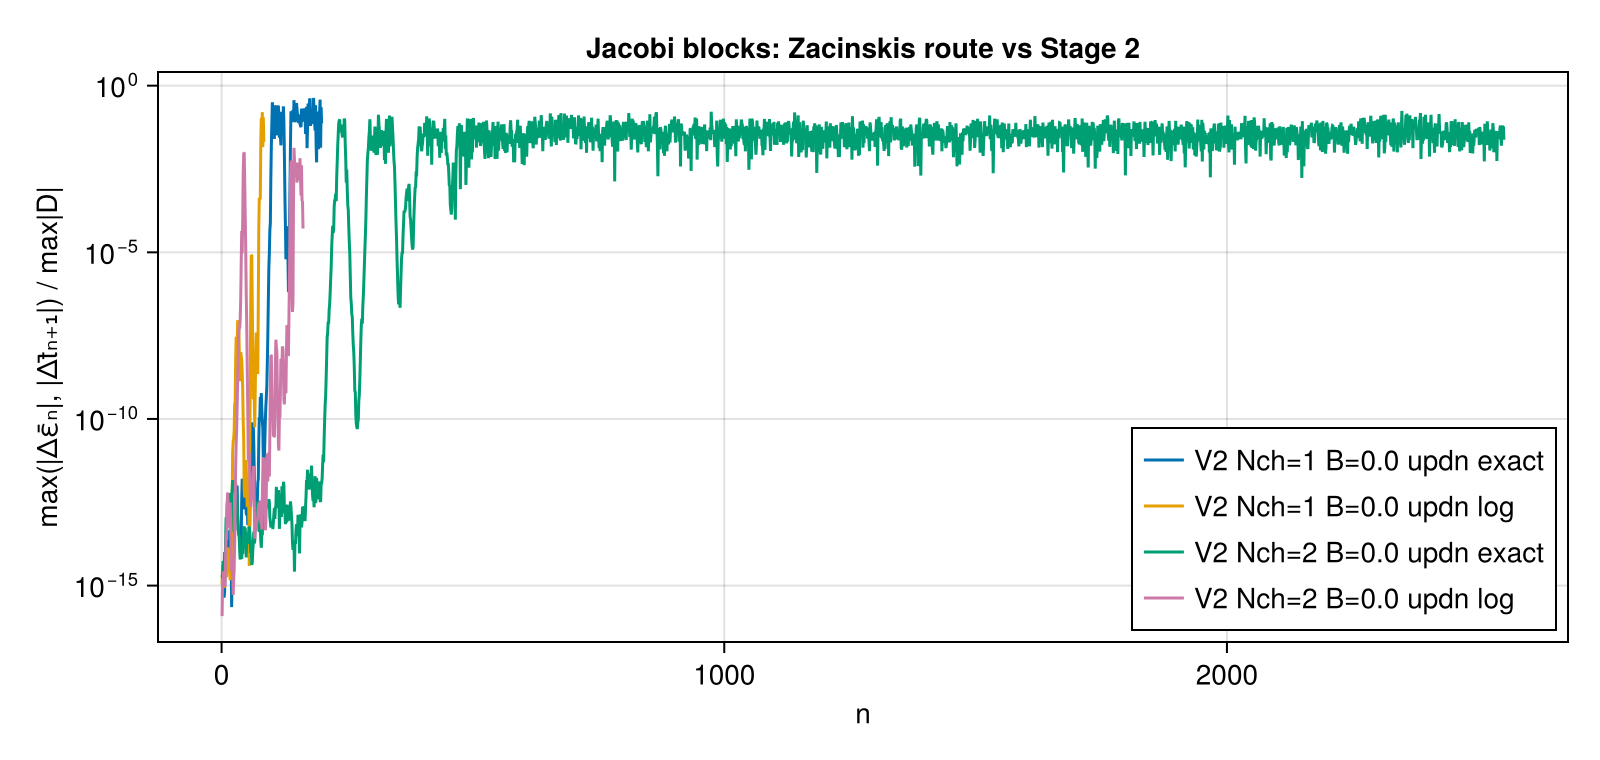

In [22]:
# Zacinskis cross-check (C2, [VD] Prop. 11)
@printf("%-30s %9s %9s %9s %9s %9s %7s %7s %7s\n", "case", "S-N̄²", "Ū₁", "spectra", "weights", "Σ^S", "L_zac", "L", "n_agree")
for k in vcat(["V2 Nch=$N B=0.0 $c $g" for N in (1, 2) for c in (:updn, :upup) for g in (:exact, :log)], ["V1 atom T=0.1 updn"])
    z = R[k][:checks][:zac]
    @printf("%-30s %9.1e %9.1e %9.1e %9.1e %9.1e %7d %7d %7d\n", k, z.S_err, z.U1_err, z.spec_err, z.weight_err, z.sigma_err, z.L_zac, z.L_chain, z.n_agree)
end
fig = Figure(size = (800, 380))
ax = Axis(fig[1, 1]; yscale = log10, xlabel = "n", ylabel = "max(|Δε̄ₙ|, |Δt̄ₙ₊₁|) / max|D|", title = "Jacobi blocks: Zacinskis route vs Stage 2")
for k in ("V2 Nch=1 B=0.0 updn exact", "V2 Nch=1 B=0.0 updn log", "V2 Nch=2 B=0.0 updn exact", "V2 Nch=2 B=0.0 updn log")
    z = R[k][:checks][:zac]
    lines!(ax, eachindex(z.block_dev), fl.(z.block_dev); label = k)
end
axislegend(ax; position = :rb)
savefig("zacinskis_blocks", fig)

## 4. Untruncated NRG (V3a)

The same chains with `NRGParams(N = Nch, Nkeep = typemax(Int))`: without truncation the Anders–Schiller basis is the
exact eigenbasis, so NRG data must equal the binned ED data of V2b (mpNRG V3c accuracy, about $10^{-14}$), and all
guaranteed checks must hold. `DiscreteData` from NRG and from ED are compared directly.

In [23]:
@printf("%-30s %9s %9s %9s\n", "case", "max|ΔW̃|", "max|Δw^B|", "max|Δs|")
for N in (1, 2), f in (0.0, 0.05), c in (:updn, :upup)
    k = "V3a Nch=$N B=$f $c"; df = R[k][:diff]
    @printf("%-30s %9.1e %9.1e %9.1e\n", k, df.W, df.wB, df.s)
end
println()
chain_table(["V3a Nch=$N B=$f $c" for N in (1, 2) for f in (0.0, 0.05) for c in (:updn, :upup)])

case                             max|ΔW̃| max|Δw^B|   max|Δs|
V3a Nch=1 B=0.0 updn             4.4e-15   3.6e-16   2.8e-15


V3a Nch=1 B=0.0 upup             4.4e-15   5.8e-16   5.2e-16
V3a Nch=1 B=0.05 updn            1.7e-15   5.8e-16   8.6e-16
V3a Nch=1 B=0.05 upup            1.7e-15   3.6e-16   3.5e-16
V3a Nch=2 B=0.0 updn             9.2e-15   9.4e-16   4.7e-15
V3a Nch=2 B=0.0 upup             9.2e-15   7.9e-16   1.4e-15
V3a Nch=2 B=0.05 updn            5.3e-15   1.1e-15   3.2e-15
V3a Nch=2 B=0.05 upup            5.3e-15   3.4e-16   7.7e-16

case                                 bins     R    L  L_B        C1        C2        C3        C4   C4 unst        C5        C6        C7        C8     t [s]
V3a Nch=1 B=0.0 updn                  195    87   86   55   2.0e-15   7.0e-14   2.0e-01   3.7e-01         —   0.0e+00   5.2e-16   5.8e-16   3.1e-15      25.5
V3a Nch=1 B=0.0 upup                  195    87   86   55   2.0e-15   7.0e-14   2.0e-01   3.7e-01         —   0.0e+00   7.2e-16   5.0e-16   3.3e-14       1.0
V3a Nch=1 B=0.05 updn                 195   102  101   57   2.6e-15   3.6e-14   2.4e-01   5.7e-01 

max|K̃(NRG) - K̃(ED)| / max|K̃| = 2.4e-14


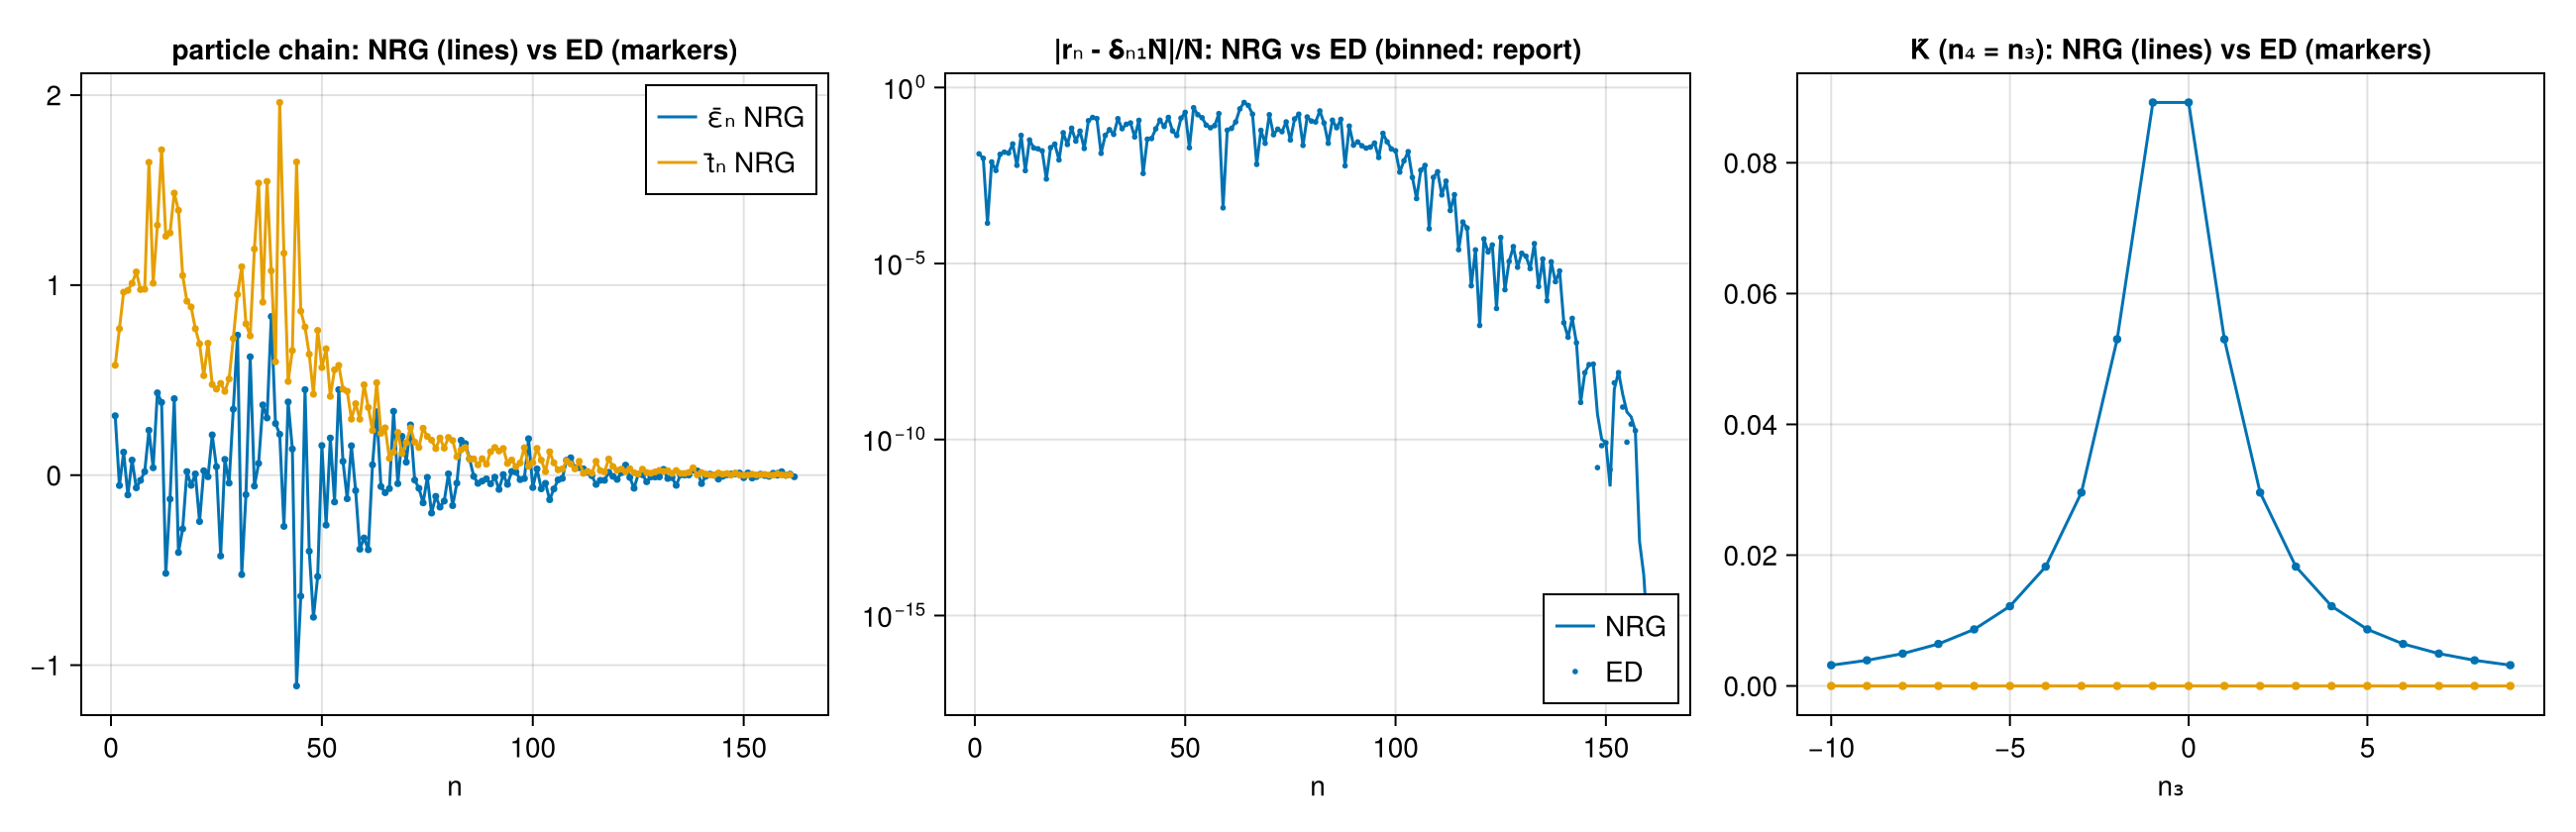

In [24]:
fig = Figure(size = (1300, 420))
o = R["V3a Nch=2 B=0.0 updn"]; e = R["V2 Nch=2 B=0.0 updn log"]
ch = o[:res].ch; che = e[:res].ch
ax = Axis(fig[1, 1]; xlabel = "n", title = "particle chain: NRG (lines) vs ED (markers)")
lines!(ax, [real(x[1]) for x in ch.Jbar.eps]; label = "ε̄ₙ NRG"); scatter!(ax, [real(x[1]) for x in che.Jbar.eps]; markersize = 5)
lines!(ax, [real(x[1]) for x in ch.Jbar.lower]; label = "t̄ₙ NRG"); scatter!(ax, [real(x[1]) for x in che.Jbar.lower]; markersize = 5)
axislegend(ax)
ax = Axis(fig[1, 2]; yscale = log10, xlabel = "n", title = "|rₙ - δₙ₁N̄|/N̄: NRG vs ED (binned: report)")
lines!(ax, fl.(HA.leakage_profile(ch)); label = "NRG"); scatter!(ax, fl.(HA.leakage_profile(che)); markersize = 4, label = "ED")
axislegend(ax; position = :rb)
bx = o[:checks][:box]; bxe = e[:checks][:box]
ax = Axis(fig[1, 3]; xlabel = "n₃", title = "K̃ (n₄ = n₃): NRG (lines) vs ED (markers)")
lines!(ax, bx.n3s, [real(bx.Kt[i, i]) for i in eachindex(bx.n3s)]); scatter!(ax, bxe.n3s, [real(bxe.Kt[i, i]) for i in eachindex(bxe.n3s)]; markersize = 6)
lines!(ax, bx.n3s, [imag(bx.Kt[i, i]) for i in eachindex(bx.n3s)]); scatter!(ax, bxe.n3s, [imag(bxe.Kt[i, i]) for i in eachindex(bxe.n3s)]; markersize = 6)
m_ = .!isnan.(real.(bx.Kt))
@printf("max|K̃(NRG) - K̃(ED)| / max|K̃| = %.1e\n", maximum(abs, bx.Kt[m_] - bxe.Kt[m_]) / maximum(abs, bxe.Kt[m_]))
savefig("v3a_overlay", fig)

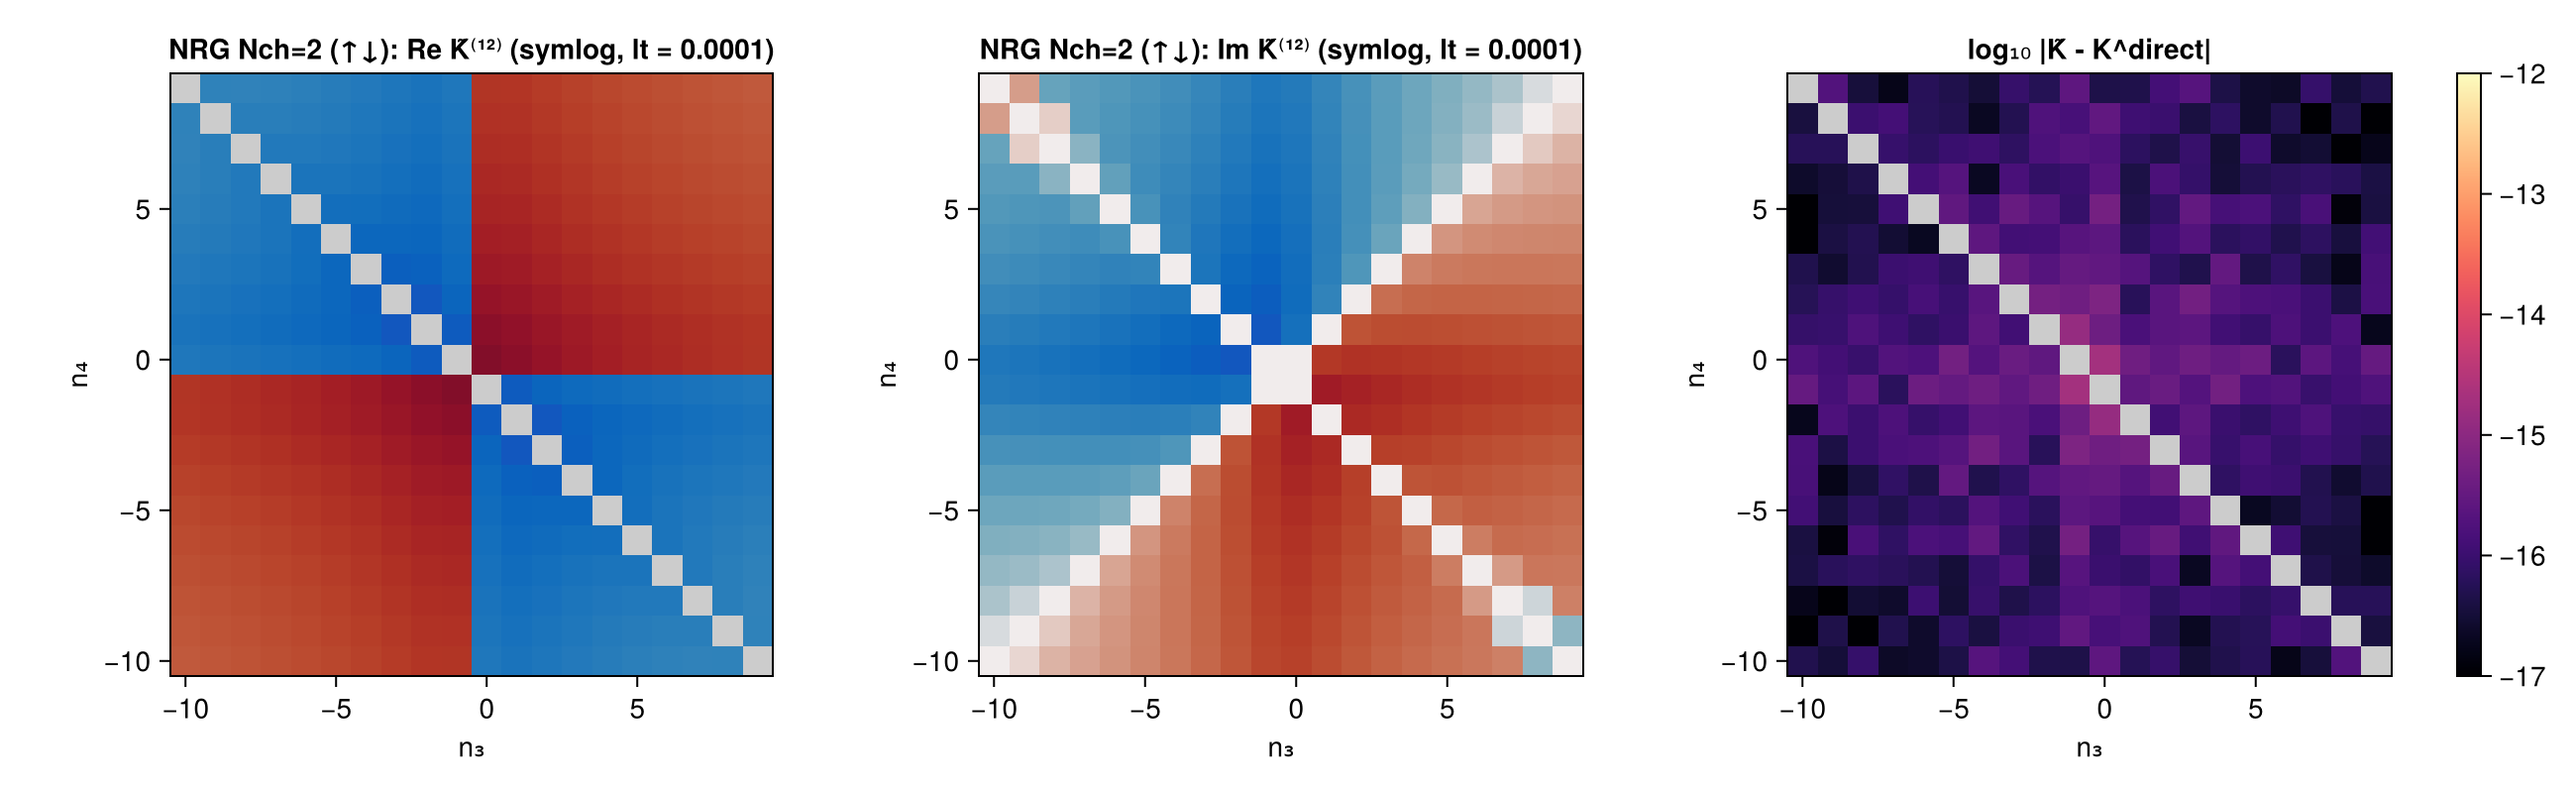

In [25]:
savefig("v3a_K", K_heatmaps(R["V3a Nch=2 B=0.0 updn"][:checks][:box]; title = "NRG Nch=2 (↑↓)"))

## 5. Decoupled tail, truncated NRG (V3b)

As mpNRG V4d: chain of length 3 with $t_n=\varepsilon_n=0$ for $n>n_c=1$, `Nkeep = 40`, $T=0.05$. With the decoupled
tail the Anders–Schiller states are exact eigenstates and the NRG approximation, the shell-diagonal expansion and the
slicing are exact, so **truncated** NRG data equal ED of the same chain; this is the only regime in which truncated data
are exact. Compared with ED of the same chain on the same grid. A failure here would be a bug, not NRG physics.

In [26]:
for c in (:updn, :upup)
    o = R["V3b $c"]; tr = o[:data].meta[:truncation]; df = o[:diff]
    @printf("%s: kept per shell %s, discarded %s; data vs ED: max|ΔW̃| = %.1e, max|Δw^B| = %.1e, max|Δs| = %.1e\n",
            chs(c), tr.kept, tr.disc, df.W, df.wB, df.s)
end
println()
chain_table(["V3b updn", "V3b upup"])
println("\nED of the same chain (binned, same grid):")
for c in (:updn, :upup)
    ce = R["V3b $c"][:ed][:checks]
    @printf("  %s: C1 %.1e  C5 %.1e  C6 %.1e  C7 %.1e  C8 %.1e; K̃(NRG) vs K̃(ED): %.1e\n", chs(c), ce[:C1], ce[:C5], ce[:C6], ce[:C7], ce[:C8],
            (bx = R["V3b $c"][:checks][:box]; bxe = ce[:box]; m_ = .!isnan.(real.(bx.Kt)); maximum(abs, bx.Kt[m_] - bxe.Kt[m_]) / maximum(abs, bxe.Kt[m_])))
end

(↑↓): kept per shell [16, 42, 40, 0], discarded [0, 22, 128, 160]; data vs ED: max|ΔW̃| = 3.2e-15, max|Δw^B| = 7.2e-16, max|Δs| = 2.8e-15
(↑↑): kept per shell [16, 42, 40, 0], discarded [0, 22, 128, 160]; data vs ED: max|ΔW̃| = 3.2e-15, max|Δw^B| = 5.4e-16, max|Δs| = 4.9e-16



case                                 bins     R    L  L_B        C1        C2        C3        C4   C4 unst        C5        C6        C7        C8     t [s]
V3b updn                              195    87   86   55   1.2e-15   7.1e-14   2.0e-01   3.7e-01         —   0.0e+00   3.7e-16   4.9e-16   3.4e-15       2.7
V3b upup                              195    87   86   55   1.2e-15   7.1e-14   2.0e-01   3.7e-01         —   0.0e+00   1.1e-15   9.9e-16   3.1e-14       2.0

ED of the same chain (binned, same grid):
  (↑↓): C1 2.1e-15  C5 0.0e+00  C6 3.2e-16  C7 4.9e-16  C8 3.2e-15; K̃(NRG) vs K̃(ED): 2.9e-15
  (↑↑): C1 2.1e-15  C5 0.0e+00  C6 6.8e-16  C7 4.0e-16  C8 2.8e-14; K̃(NRG) vs K̃(ED): 2.7e-14


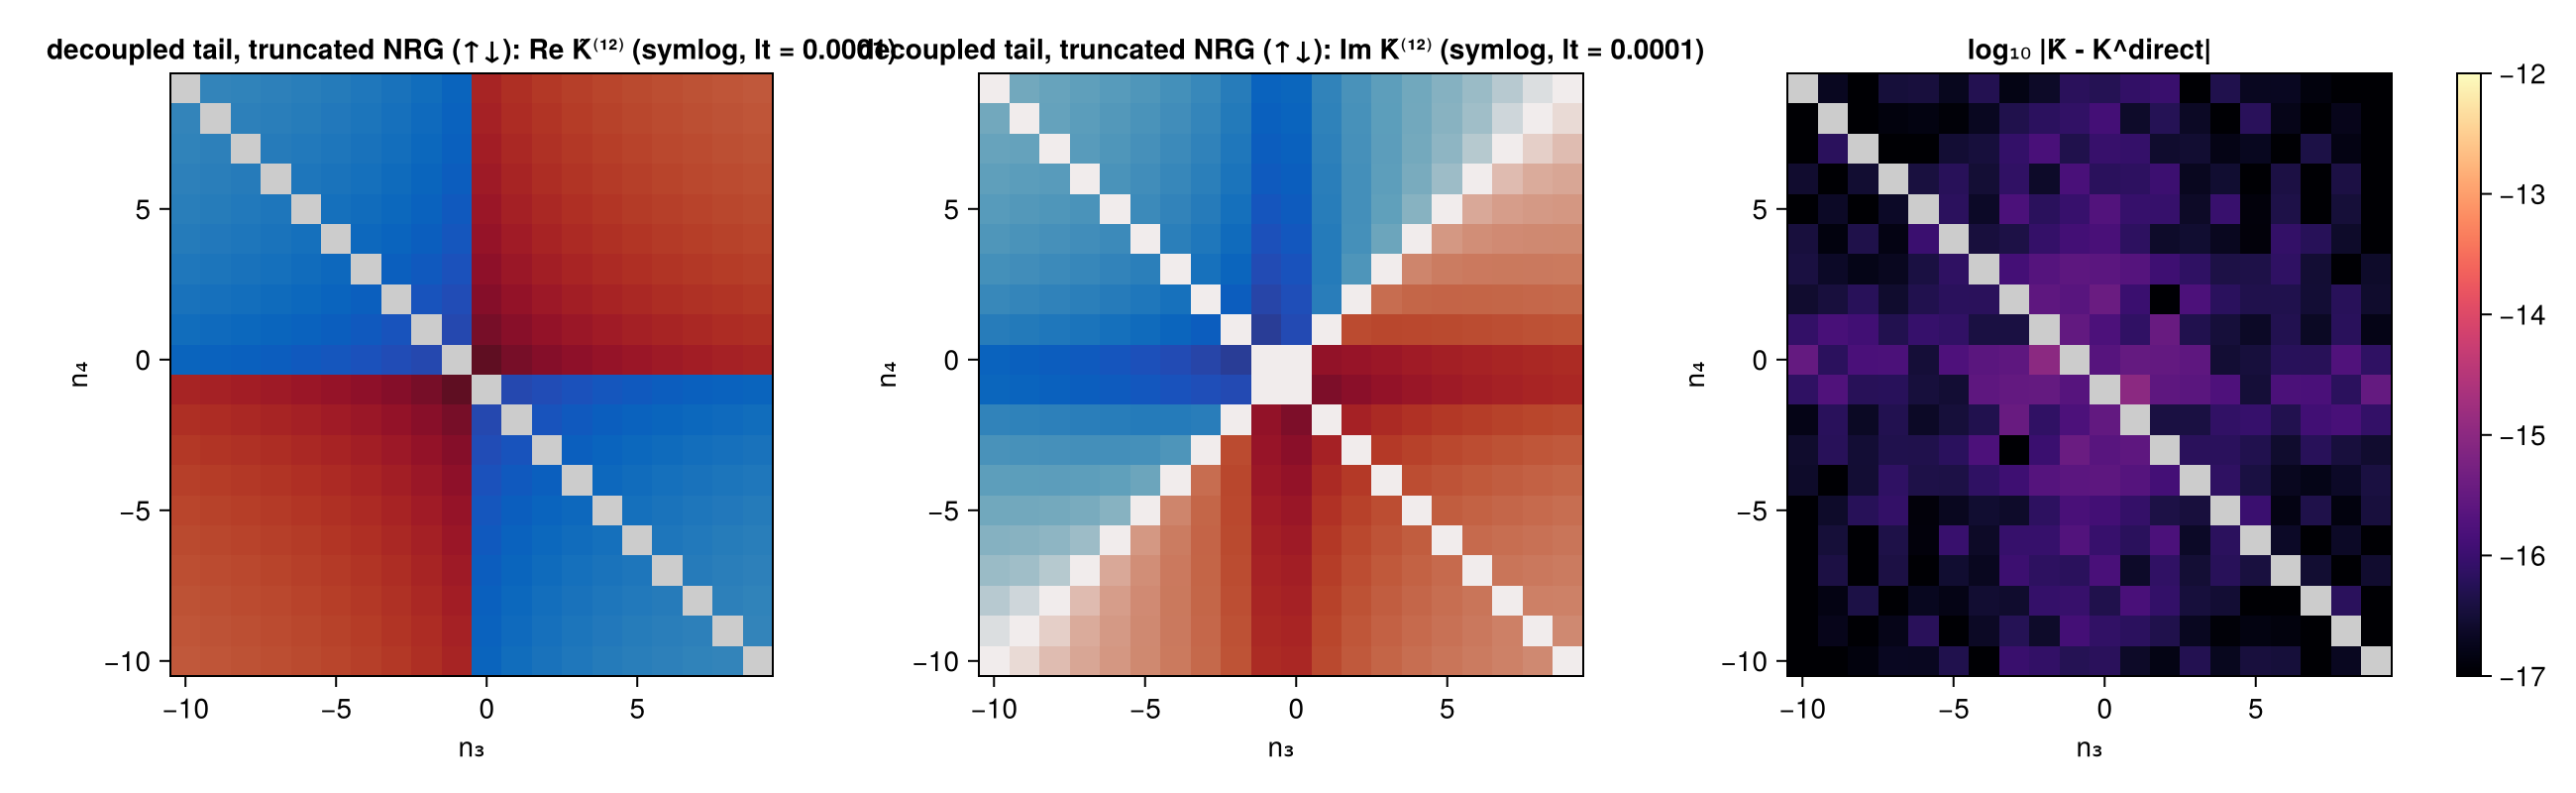

In [27]:
savefig("v3b_K", K_heatmaps(R["V3b updn"][:checks][:box]; title = "decoupled tail, truncated NRG (↑↓)"))

## 6. Physical chain, truncated NRG (V3c)

`siam(U = 0.5, εd = -0.1, Δ = 0.1)` on the physical Wilson chain, $\Lambda=4$, $z=1$, length
`chain_length_for(T; Λ = 4)` (as the mpNRG validation runs), $N_{\rm keep}\in\{64,128,256,512\}$,
$T\in\{10^{-2},10^{-4}\}$, both channels, on `LogGrid(emin = 1e-9, emax = 10, ndec = 16)` (deviation from the default
`emin = 1e-5`, which clamps millions of contributions at $T=10^{-4}$; see `vertex_krylov_STATUS.md`). Truncated NRG data
are **not** exact data of a single generator, so nothing is guaranteed: every check is reported. The central question
is how much the inconsistency of the NRG data, measured by the factorization residual C7, costs in the vertex, measured
by C8 against the direct estimator from the same PSFs. C1 is algebraic (it holds for any Hermitian data); C3 uses the
$U=0$ propagator of the same chain from its single-particle Hamiltonian (`vk_G0_chain`); C4 has no guarantee for
binned NRG data (Prop. 13 does not apply). Convergence in $N_{\rm keep}$ is measured against $N_{\rm keep}=512$.

Truncated NRG weights violate two preconditions of Stage 1 that exact and binned ED data satisfy to rounding: the
$2N\times2N$ Pelz weights $\widetilde{\mathbf W}_\beta$ are not Hermitian bin by bin (their sum is), and their Hermitian
part is not positive semidefinite. Stage 1 factors the Hermitian part and drops its negative eigenvalues (both
reported below), so the factored measure has $v^\dagger v\neq1$. Where the specified assertion
$\|v^\dagger v-1\|\le10^{-12}$ fails, Stage 1 runs with the opt-in variant `gram = :general`
($P=1-v(v^\dagger v)^{-1}v^\dagger$, $\sigma=(v^\dagger v)^{-1}v^\dagger w$; identical to the specification for
$v^\dagger v=1$; deviation in `vertex_krylov_STATUS.md`). All checks compare with the raw data, so C1 and C8 include
the cost of what Stage 1 drops.

In [28]:
V3CK = [(T, Nk, c) for T in V3C_TS for Nk in V3C_NKEEPS for c in (:updn, :upup)]
v3(T, Nk, c) = R["V3c T=$T Nk=$Nk $c"]
@printf("%-8s %6s %-5s %3s %5s %5s %5s %5s %4s %9s %9s %9s %9s %9s %9s %9s %9s %8s %7s\n", "T", "Nkeep", "chan", "N", "kept",
        "bins", "R", "L", "L_B", "C1", "C2", "C3", "C4", "C5", "C6", "C7", "C8", "clamped", "t_NRG")
for (T, Nk, c) in V3CK
    o = v3(T, Nk, c); ck = o[:checks]; d = o[:data]
    @printf("%-8.0e %6d %-5s %3d %5d %5d %5d %5d %4d %9.1e %9.1e %9.1e %9.1e %9.1e %9.1e %9.1e %9.1e %8d %7.0f\n", T, Nk, c,
            d.meta[:N], maximum(d.meta[:truncation].kept), count(β -> !iszero(d.W[β]), eachindex(d.b)), ck[:R], ck[:L], ck[:LB],
            ck[:C1], ck[:C2], ck[:C3], ck[:C4], ck[:C5], ck[:C6], ck[:C7], ck[:C8], d.meta[:nclamped], d.meta[:time_nrg] + d.meta[:time_data])
end
println("\nsanity (sum rules vs thermal_average_product, 3p totals, PSD), max over V3c:")
S = [v3(k...)[:checks][:sanity] for k in V3CK]
@printf("  herm %.1e, min eig/max‖W‖ %.1e, sum rule %.1e, 3p totals %.1e, C5 %.1e, Boltzmann-shortcut diff %.1e\n",
        maximum(s.herm_err for s in S), minimum(s.min_eig_rel for s in S), maximum(s.sumrule_err for s in S),
        maximum(s.totals3_err for s in S), maximum(s.C5 for s in S), maximum(s.boltzmann_diff for s in S))
println("C7 per family (max over V3c): ", Dict(f => @sprintf("%.1e", maximum(v3(k...)[:checks][:C7_family][f] for k in V3CK)) for f in 1:6))

T         Nkeep chan    N  kept  bins     R     L  L_B        C1        C2        C3        C4        C5        C6        C7        C8  clamped   t_NRG
1e-02        64 updn   15    66   214   393   392  251   1.3e-03   6.5e-14   5.6e-01   4.2e-01   0.0e+00   2.3e-16   1.4e-02   1.2e-01        0      41


1e-02        64 upup   15    66   214   393   392  251   1.3e-03   6.5e-14   5.6e-01   4.2e-01   0.0e+00   1.4e-15   2.1e-02   7.9e-02        0      13
1e-02       128 updn   15   130   226   429   425  257   4.4e-04   3.0e-14   3.9e-01   4.3e-01   0.0e+00   2.0e-15   3.1e-03   5.4e-04        0      38
1e-02       128 upup   15   130   226   429   425  257   4.4e-04   3.0e-14   3.9e-01   4.3e-01   0.0e+00   1.8e-15   2.3e-03   4.6e-04        0      38
1e-02       256 updn   15   257   245   468   467  269   2.3e-06   4.7e-13   2.5e-01   5.8e-01   0.0e+00   1.5e-15   5.1e-08   9.8e-05     6108     171
1e-02       256 upup   15   257   245   468   467  269   2.3e-06   4.7e-13   2.5e-01   5.8e-01   0.0e+00   1.6e-15   2.9e-08   1.5e-04     6108     170
1e-02       512 updn   15   514   254   492   490  281   2.2e-06   5.8e-13   2.8e-01   5.4e-01   0.0e+00   2.1e-15   4.7e-08   8.9e-05    14528     686
1e-02       512 upup   15   514   254   492   490  281   2.2e-06   5.8e-13   2.8e-01   5

C7 per family (max over V3c): Dict

(3 => "1.5e-02", 2 => "2.4e-03", 1 => "2.3e-02", 4 => "3.7e-03", 5 => "3.7e-03", 6 => "1.8e-02")


In [29]:
# properties of the truncated NRG data that Stage 1 meets (report): W̃_β bin by bin is not Hermitian (Stage 1
# factors the Hermitian part) and its Hermitian part is not PSD (Stage 1 drops the negative eigenvalues), so the
# factored measure has v†v ≠ 1; where ‖v†v - 1‖ > 1e-12 Stage 1 runs with gram = :general (deviation, see STATUS);
# negative bosonic weights are clamped to 0
@printf("%-8s %6s %-5s %12s %12s %10s %8s %11s %8s %15s\n", "T", "Nkeep", "chan", "antiherm/‖W‖", "neg. mass", "worst neg",
        "#bins<0", "‖v†v - 1‖", "general", "w^B<0: n, min")
for (T, Nk, c) in V3CK
    p = v3(T, Nk, c)[:psd]
    @printf("%-8.0e %6d %-5s %12.1e %12.1e %10.1e %8d %11.1e %8s %15s\n", T, Nk, c, p.antiherm_rel, p.neg_mass, p.worst_rel,
            p.nbins_neg, p.norm_err, p.gram_general, @sprintf("%d, %.1e", p.wB_neg...))
end

T         Nkeep chan  antiherm/‖W‖    neg. mass  worst neg  #bins<0   ‖v†v - 1‖  general   w^B<0: n, min
1e-02        64 updn       7.0e-03      1.7e-04    3.4e-01       15     1.3e-04     true      0, 0.0e+00


1e-02        64 upup       7.0e-03      1.7e-04    3.4e-01       15     1.3e-04     true      0, 0.0e+00
1e-02       128 updn       3.1e-03      1.0e-05    2.8e-03       10     2.2e-06     true      0, 0.0e+00
1e-02       128 upup       3.1e-03      1.0e-05    2.8e-03       10     2.2e-06     true      0, 0.0e+00
1e-02       256 updn       2.2e-03      2.1e-13    2.5e-03        6     1.8e-13    false      0, 0.0e+00
1e-02       256 upup       2.2e-03      2.1e-13    2.5e-03        6     1.8e-13    false      0, 0.0e+00
1e-02       512 updn       1.0e-03      2.2e-13    1.4e-03        5     1.9e-13    false      0, 0.0e+00
1e-02       512 upup       1.0e-03      2.2e-13    1.4e-03        5     1.9e-13    false      0, 0.0e+00
1e-04        64 updn       6.5e-03      9.1e-04    1.0e+00       40     7.3e-04     true     7, -1.1e-05
1e-04        64 upup       6.5e-03      9.1e-04    1.0e+00       40     7.3e-04     true     7, -1.1e-05
1e-04       128 updn       3.2e-03      1.5e-05    1.0e

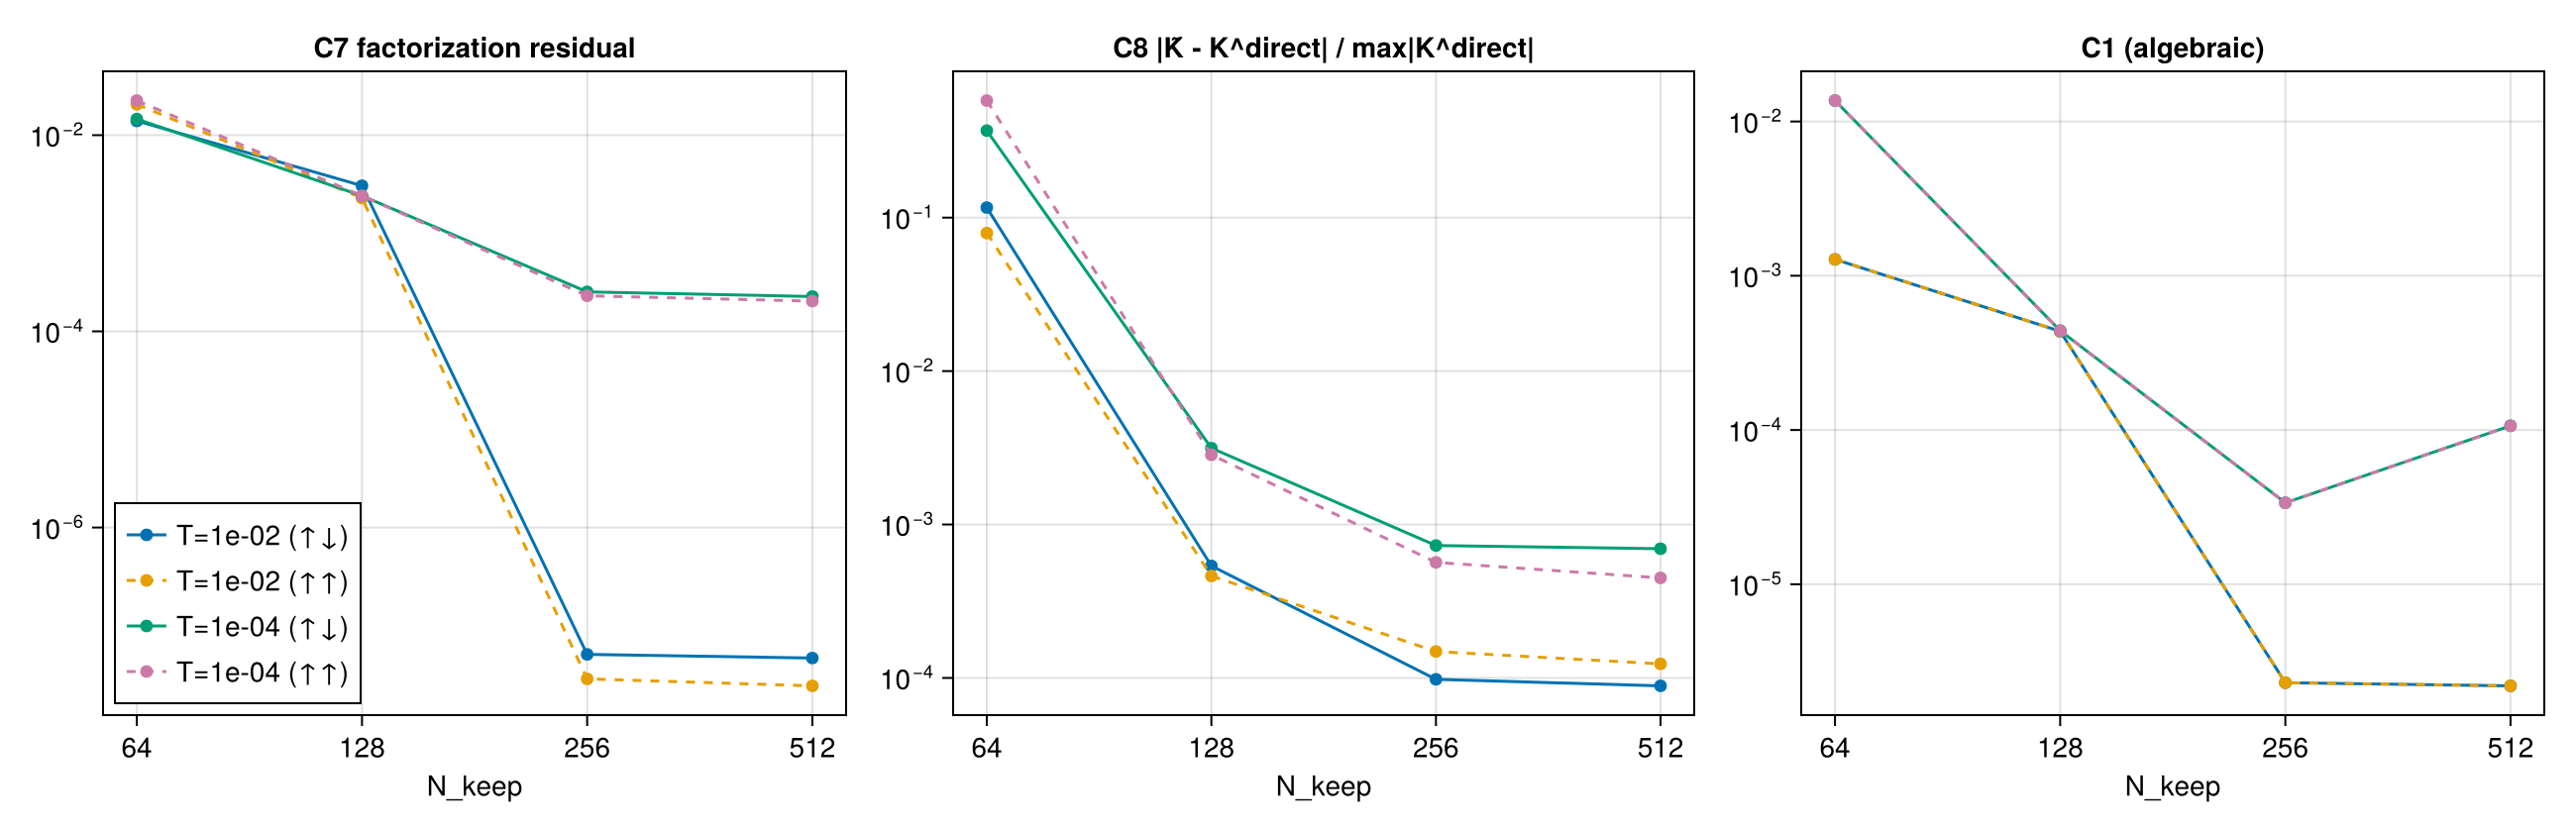

In [30]:
# C7 (data inconsistency) and C8 (cost in the vertex) against Nkeep and T
fig = Figure(size = (1300, 420))
for (j, (key, ttl)) in enumerate(((:C7, "C7 factorization residual"), (:C8, "C8 |K̃ - K^direct| / max|K^direct|"),
                                  (:C1, "C1 (algebraic)")))
    ax = Axis(fig[1, j]; xscale = log2, yscale = log10, xlabel = "N_keep", title = ttl, xticks = collect(V3C_NKEEPS))
    for T in V3C_TS, c in (:updn, :upup)
        scatterlines!(ax, collect(V3C_NKEEPS), [fl(v3(T, Nk, c)[:checks][key]) for Nk in V3C_NKEEPS];
                      label = @sprintf("T=%.0e %s", T, chs(c)), linestyle = c === :updn ? :solid : :dash)
    end
    j == 1 && axislegend(ax; position = :lb)
end
savefig("v3c_C7_C8", fig)

In [31]:
# convergence of K̃ and of K^direct in Nkeep (relative to Nkeep = 512, over the Matsubara box)
println("max|K(Nkeep) - K(512)| / max|K(512)|:")
@printf("%-8s %-5s %s\n", "T", "chan", join([@sprintf("%15s", "Nkeep=$Nk (K̃, K^dir)") for Nk in V3C_NKEEPS[1:end-1]], " "))
for T in V3C_TS, c in (:updn, :upup)
    ref = v3(T, 512, c)[:checks][:box]; m_ = .!isnan.(real.(ref.Kt))
    vals = map(V3C_NKEEPS[1:end-1]) do Nk
        bx = v3(T, Nk, c)[:checks][:box]
        @sprintf("%7.1e, %7.1e", maximum(abs, bx.Kt[m_] - ref.Kt[m_]) / maximum(abs, ref.Kt[m_]),
                 maximum(abs, bx.Kd[m_] - ref.Kd[m_]) / maximum(abs, ref.Kd[m_]))
    end
    @printf("%-8.0e %-5s %s\n", T, c, join([@sprintf("%15s", v) for v in vals], " "))
end

max|K(Nkeep) - K(512)| / max|K(512)|:
T        chan  Nkeep=64 (K̃, K^dir) Nkeep=128 (K̃, K^dir) Nkeep=256 (K̃, K^dir)
1e-02    updn  9.4e-02, 2.6e-02 1.4e-02, 1.4e-02 5.5e-03, 5.5e-03


1e-02    upup  5.9e-02, 2.0e-02 2.3e-02, 2.3e-02 6.8e-03, 6.7e-03
1e-04    updn  3.7e-01, 6.7e-01 5.3e-03, 5.6e-03 2.3e-03, 2.3e-03
1e-04    upup  4.3e-01, 4.5e-01 5.9e-03, 6.6e-03 2.1e-03, 2.1e-03


In [32]:
# particle-chain lengths and residuals, Float64 vs BigFloat (precision 128)
@printf("%-8s %6s %-5s %5s %5s %11s %11s %9s %9s %9s %8s\n", "T", "Nkeep", "chan", "L", "L_big", "resid f64", "resid big",
        "orth f64", "orth big", "C1 big", "n_agree")
for (T, Nk, c) in V3CK
    o = v3(T, Nk, c); ck = o[:checks]; b = o[:big]
    pd = o[:res] === nothing ? nothing : o[:res].ch.diag[:particle]
    @printf("%-8.0e %6d %-5s %5d %5d %11.1e %11.1e %9.1e %9.1e %9.1e %8d\n", T, Nk, c, ck[:L], b.L, ck[:particle_resid],
            Float64(b.resid), pd === nothing ? NaN : pd[:orth_loss], b.orth, b.C1, b.n_agree)
end

T         Nkeep chan      L L_big   resid f64   resid big  orth f64  orth big    C1 big  n_agree
1e-02        64 updn    392   392     1.0e-37     1.6e-82   1.7e-15   9.4e-38   1.3e-03       36


1e-02        64 upup    392   392     1.0e-37     1.6e-82   1.7e-15   9.4e-38   1.3e-03       36
1e-02       128 updn    425   425     2.4e-18     2.4e-18   1.6e-15   6.2e-38   4.4e-04      425
1e-02       128 upup    425   425     2.4e-18     2.4e-18   1.6e-15   6.2e-38   4.4e-04      425
1e-02       256 updn    467   467     4.9e-39     3.1e-49   2.0e-15   2.6e-36   2.3e-06      467
1e-02       256 upup    467   467     4.9e-39     3.1e-49   2.0e-15   2.6e-36   2.3e-06      467
1e-02       512 updn    490   490     3.5e-23     2.6e-33   1.8e-15   3.9e-37   2.2e-06      490
1e-02       512 upup    490   490     3.5e-23     2.6e-33   1.8e-15   3.9e-37   2.2e-06      490
1e-04        64 updn    479   479     6.7e-14     6.7e-14   1.7e-15   7.6e-38   1.4e-02       36
1e-04        64 upup    479   479     6.7e-14     6.7e-14   1.7e-15   7.6e-38   1.4e-02       36
1e-04       128 updn    529   529     2.5e-12     2.5e-12   1.6e-15   1.1e-37   4.4e-04      529
1e-04       128 upup    529   

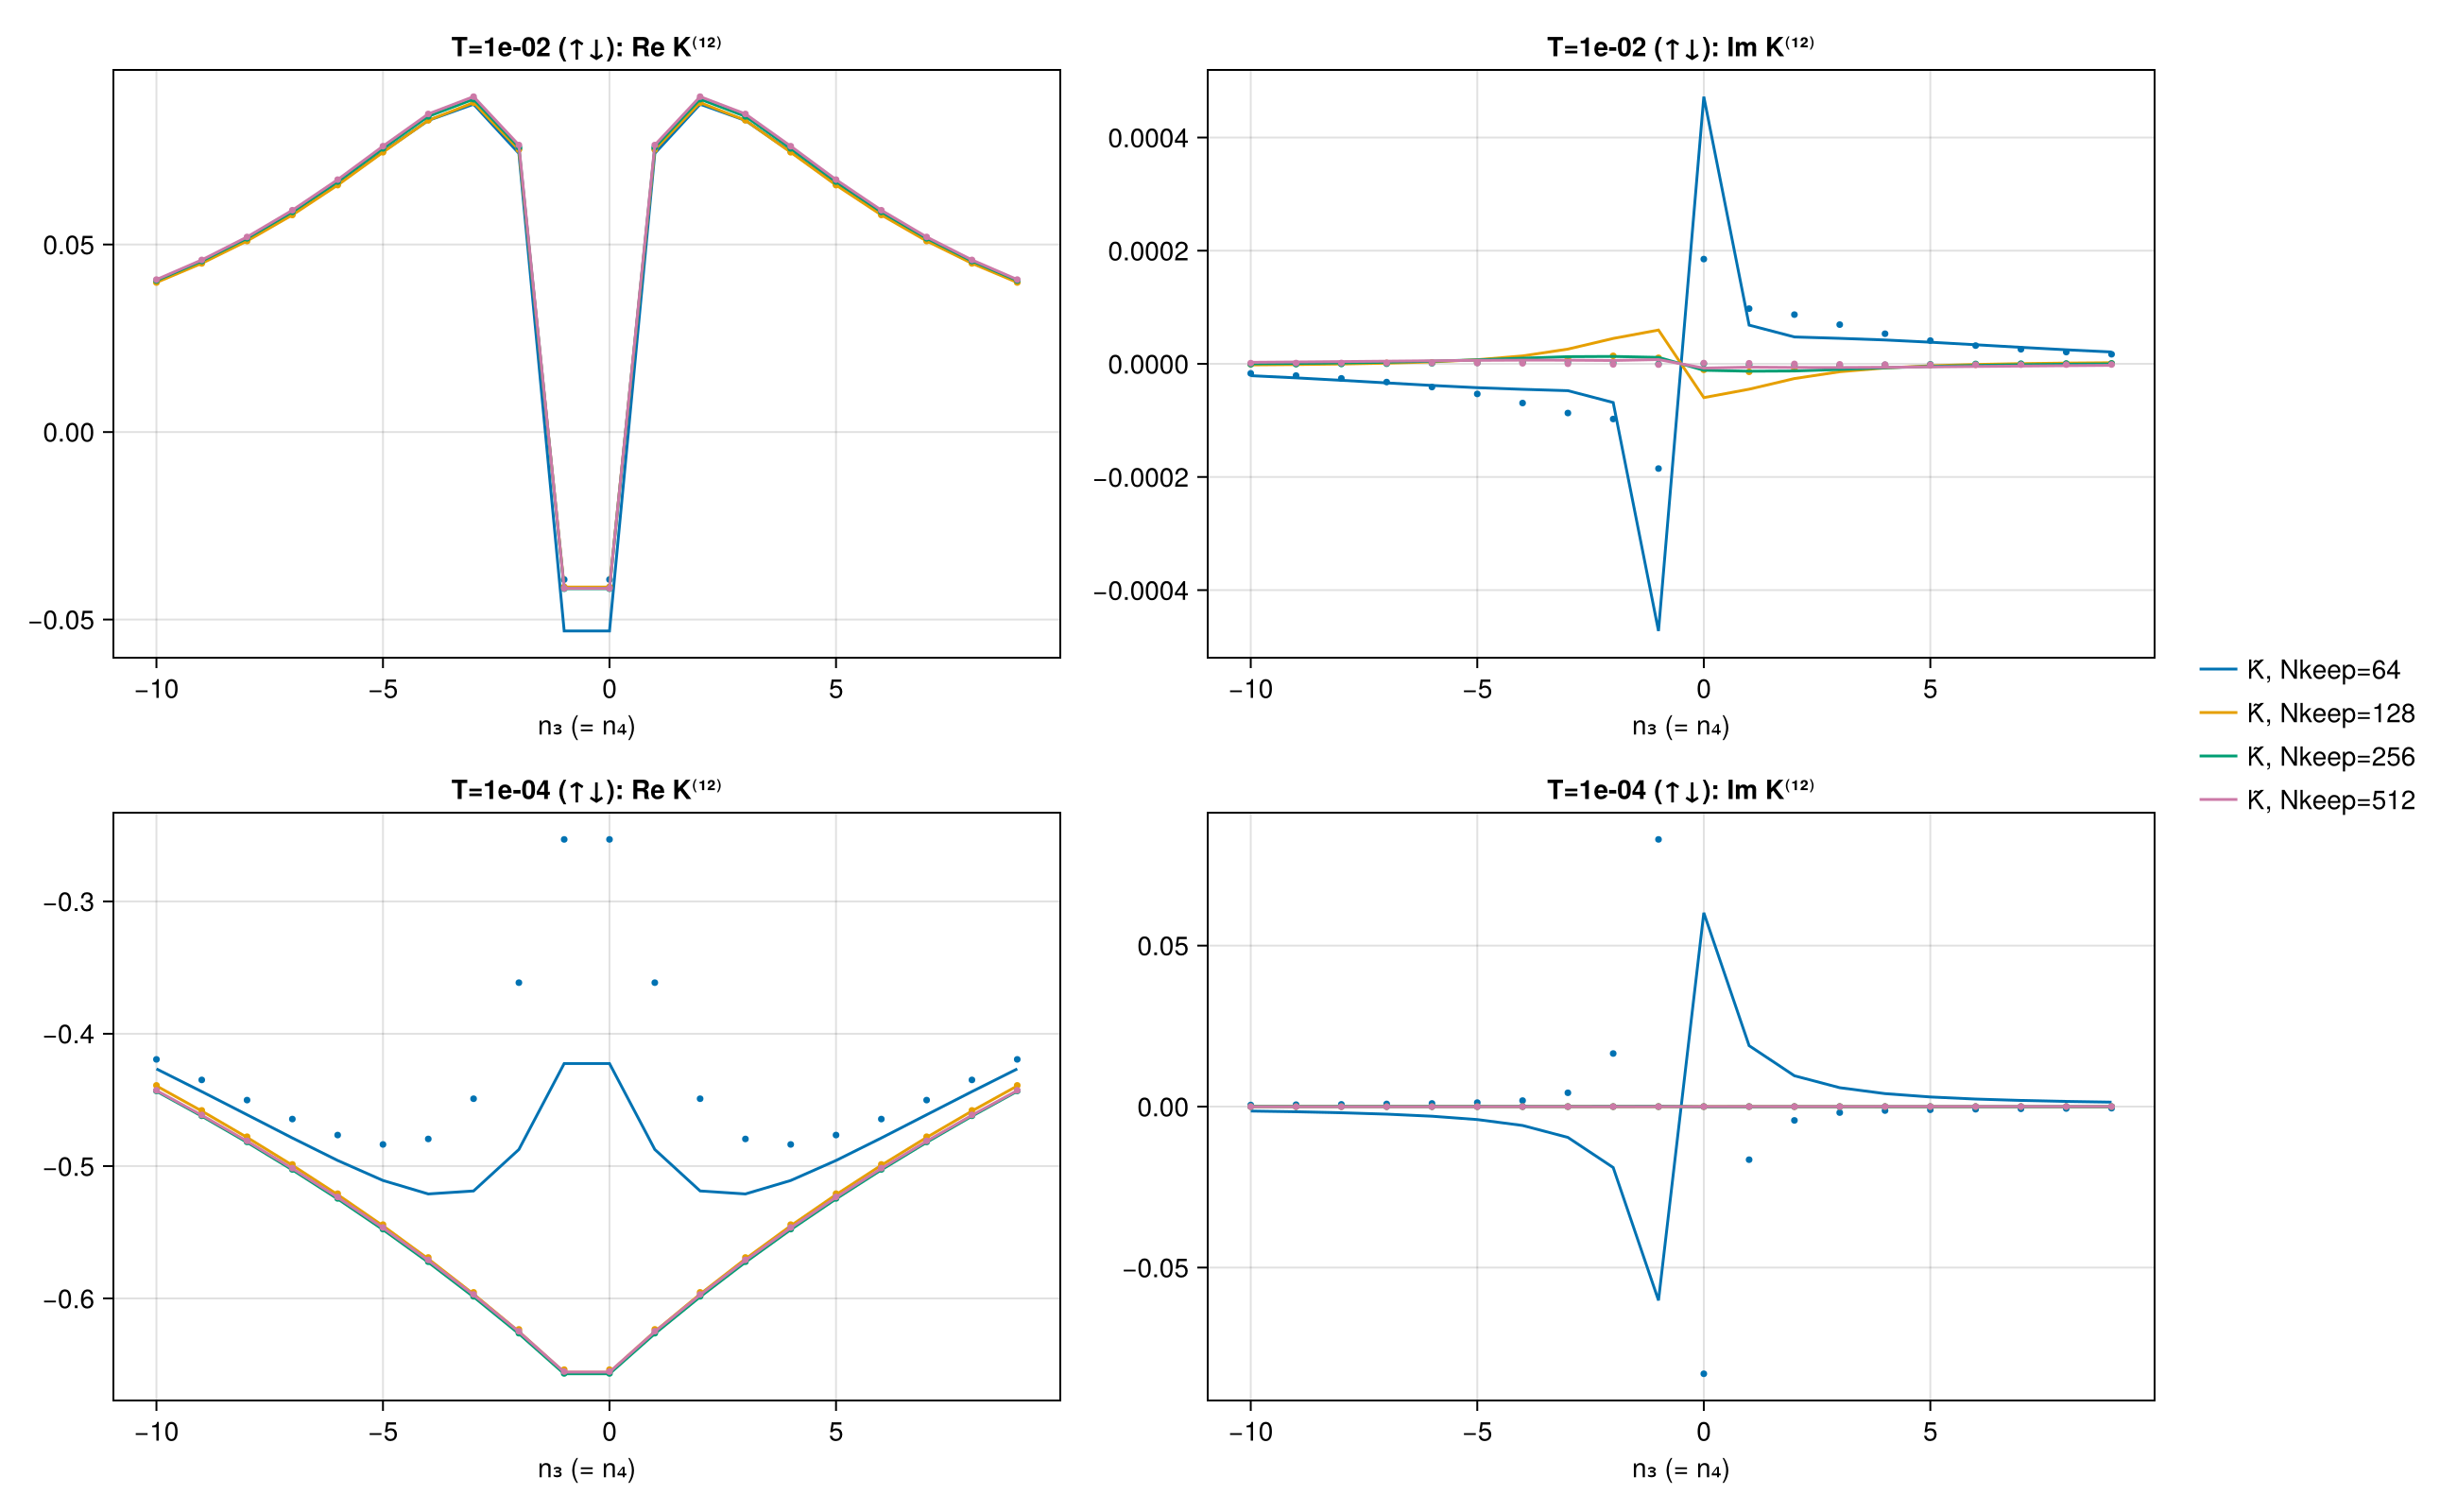

In [33]:
# K̃ slices (n4 = n3) for all Nkeep, with K^direct (markers), channel (↑↓)
fig = Figure(size = (1300, 800))
for (i, T) in enumerate(V3C_TS), (j, part) in enumerate((real, imag))
    ax = Axis(fig[i, j]; xlabel = "n₃ (= n₄)", title = @sprintf("T=%.0e (↑↓): %s K⁽¹²⁾", T, part === real ? "Re" : "Im"))
    for Nk in V3C_NKEEPS
        bx = v3(T, Nk, :updn)[:checks][:box]
        lines!(ax, bx.n3s, [part(bx.Kt[k, k]) for k in eachindex(bx.n3s)]; label = "K̃, Nkeep=$Nk")
        scatter!(ax, bx.n3s, [part(bx.Kd[k, k]) for k in eachindex(bx.n3s)]; markersize = 5)
    end
    i == 1 && j == 2 && Legend(fig[1:2, 3], ax; framevisible = false)
end
savefig("v3c_K_slices", fig)

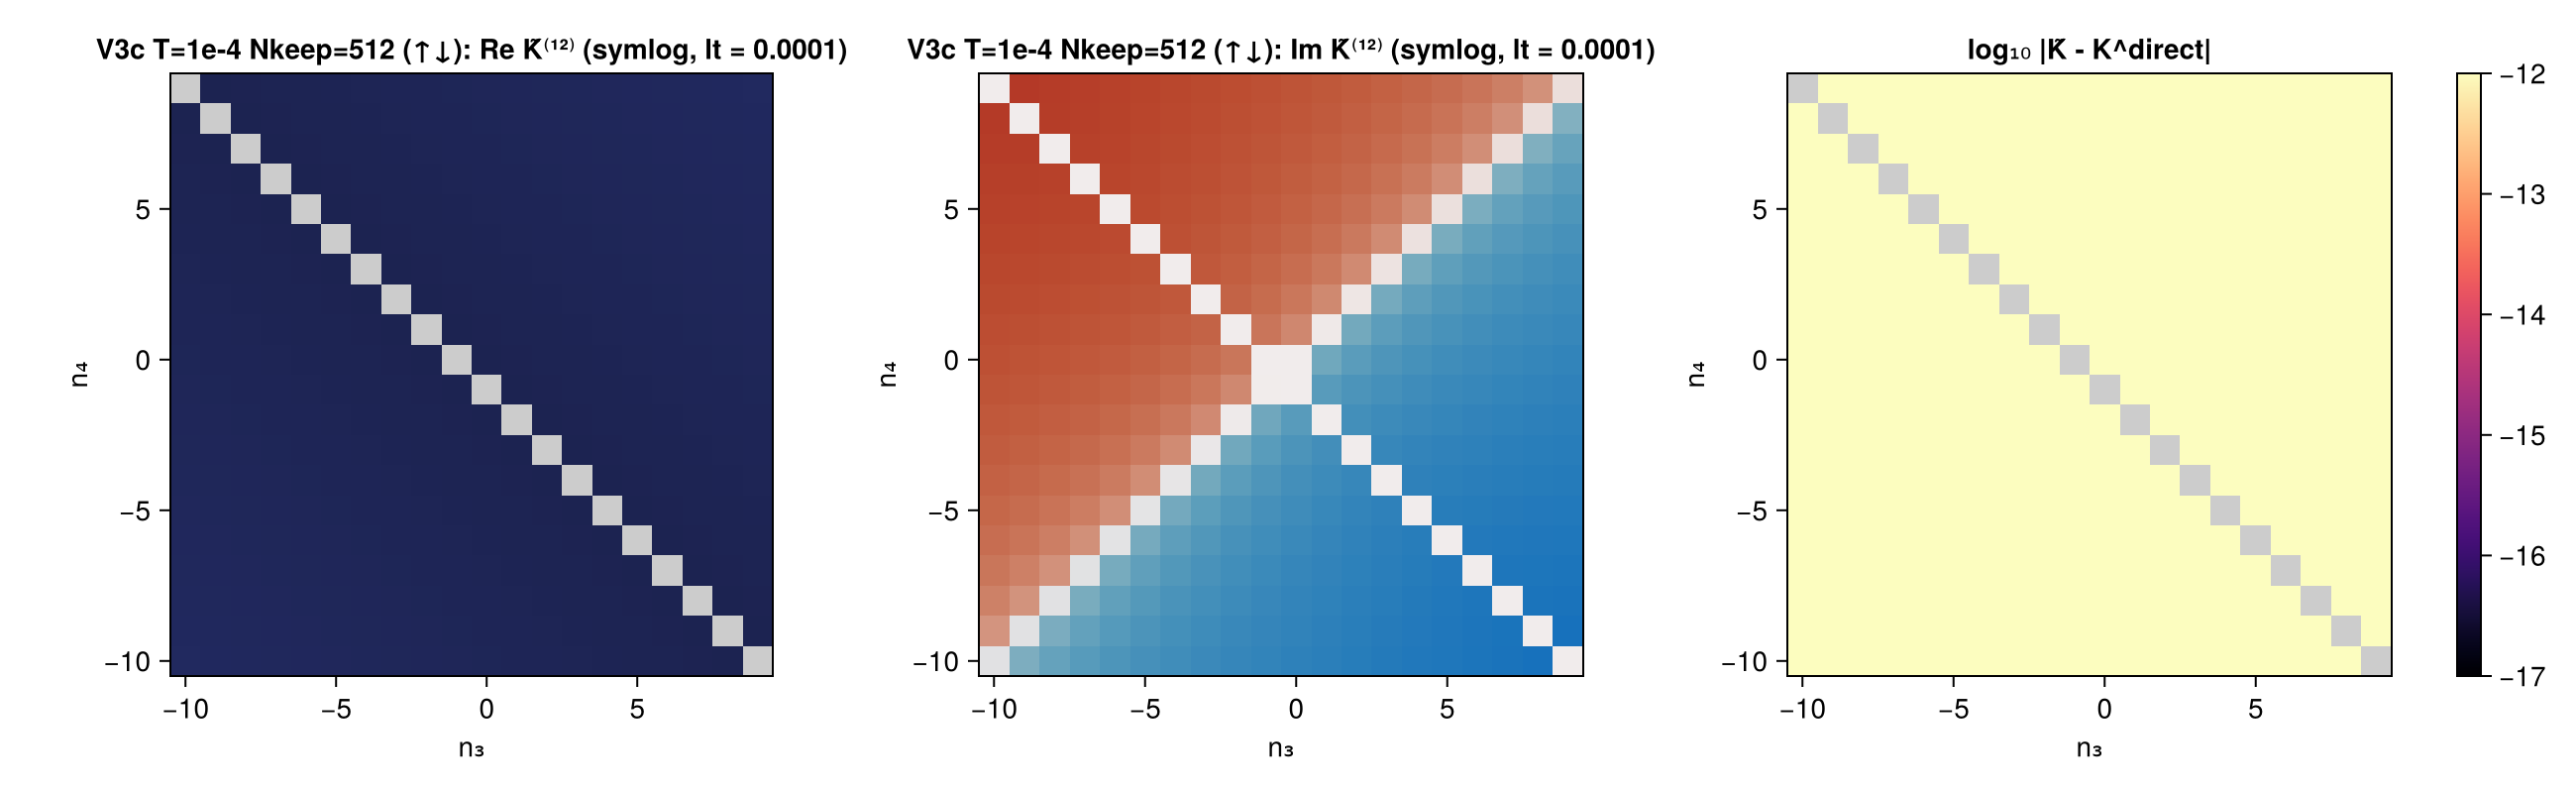

In [34]:
savefig("v3c_K", K_heatmaps(v3(1e-4, 512, :updn)[:checks][:box]; title = "V3c T=1e-4 Nkeep=512 (↑↓)"))

In [35]:
# Zacinskis cross-check on V3c data (C2 invariants; Jacobi blocks: n_agree)
@printf("%-26s %9s %9s %9s %9s %9s %7s %7s %7s\n", "case", "S-N̄²", "Ū₁", "spectra", "weights", "Σ^S", "L_zac", "L", "n_agree")
for (T, Nk, c) in V3CK
    z = v3(T, Nk, c)[:checks][:zac]
    @printf("%-26s %9.1e %9.1e %9.1e %9.1e %9.1e %7d %7d %7d\n", @sprintf("T=%.0e Nk=%d %s", T, Nk, c), z.S_err, z.U1_err,
            z.spec_err, z.weight_err, z.sigma_err, z.L_zac, z.L_chain, z.n_agree)
end

case                            S-N̄²        Ū₁   spectra   weights       Σ^S   L_zac       L n_agree
T=1e-02 Nk=64 updn           9.4e-16   2.1e-16   4.5e-15   6.5e-14   1.9e-14     392     392      32
T=1e-02 Nk=64 upup           9.4e-16   2.1e-16   4.5e-15   6.5e-14   1.9e-14     392     392      32
T=1e-02 Nk=128 updn          2.4e-16   1.1e-16   2.9e-15   3.0e-14   1.3e-14     425     425      33
T=1e-02 Nk=128 upup          2.4e-16   1.1e-16   2.9e-15   3.0e-14   1.3e-14     425     425      33
T=1e-02 Nk=256 updn          9.4e-16   4.4e-14   3.4e-15   4.7e-13   8.6e-14     467     467      33
T=1e-02 Nk=256 upup          9.4e-16   4.4e-14   3.4e-15   4.7e-13   8.6e-14     467     467      33
T=1e-02 Nk=512 updn          2.4e-16   4.7e-14   5.8e-15   5.8e-13   1.0e-13     490     490      33
T=1e-02 Nk=512 upup          2.4e-16   4.7e-14   5.8e-15   5.8e-13   1.0e-13     490     490      33
T=1e-04 Nk=64 updn           0.0e+00   1.4e-16   4.0e-15   1.3e-13   4.7e-14     478     4

## 7. Findings

The numbers behind each finding are computed in the cell below the text.

**F1 — the unstabilized particle chain leaks into the single-particle subspace (C4 report, amendment A1).** The
particle chain of Algorithm 2 with $\Pi=1-vv^\dagger$ keeps running after the cyclic space of $Qq^\dagger$ is
exhausted and enters the single-particle invariant subspace $\mathbb K_0\ominus d^\dagger$ ([VD] Lemma 12), where
$r_n=\bar U_n^\dagger Dv$ is $O(1)$. Step 1 classified this as the failure of a guaranteed check; on review it is a
mis-specification of the task sheet: for exact data with a bath C4 is guaranteed only for the stabilized chain of
Prop. 13, which is now the default output of Stage 2 (amendments A1, A2). Evidence (cell below and Sec. 3):

* the leak $|r_n-\delta_{n1}\bar N|/\bar N$ starts at rounding level at $n=1$ and grows roughly exponentially along the
  chain ("bath leakage" plot); the unstabilized chain is longer than the stabilized one by $\dim\Omega-1$, the number
  of bath levels;
* BigFloat (128 bit) gives the same leak, so the seed is not rounding in the Lanczos recursion but the accuracy with
  which the Float64 ED data satisfy the equation of motion; the recursion amplifies this component until the residual
  exceeds the termination threshold `tol·max|D|` and the chain continues into the invariant subspace;
* with the stabilization ($\Pi=1-\Omega\Omega^\dagger$, $\dim\Omega$ = number of chain levels) C4 is at rounding
  level, and $\Sigma^{\rm S}$, $\tilde K$ are unchanged; C1 and C8 of the unstabilized chain also hold: the spurious
  levels carry no weight in $\Sigma^{\rm S}$ or $\tilde K$.

Smallest reproducing case: `siam(U = 0.5, εd = -0.1, Δ = 0.1)`, chain sites $-1..0$ (16 states), $T=0.05$, ExactGrid,
channel (↑↓) (`V2 Nch=0`). Lemma 12 holds in exact arithmetic **with exact data**; Float64 data are exact only to
rounding, which the unprojected invariant subspace does not forgive ([VD] Sec. 9: "such errors can grow along the
chain").

**F2 — C2: the Jacobi blocks of two Lanczos runs agree only on the leading blocks.** The Zacinskis route
($\Omega'$ diagonalized, Lanczos from the image of $\bar U_1$) reproduces $S=\bar N^2$, the start block, the spectrum
and first-block weights of $PDP$ on ${\rm ran}\,P$, and $\Sigma^{\rm S}$ (C2 invariants, guaranteed under A3). Its
Jacobi blocks agree with Stage 2 only up to `n_agree` and its chain may terminate at a different length: the measures
have weights spanning $\sim e^{-|E|/T}$, many decades, and the late Jacobi coefficients of such measures are
ill-conditioned (they are fixed by poles whose weights are near the termination threshold). Reported (A3).

**F3 — $K^{(12)}\equiv0$ in the atom's (↑↑) channel.** $B=q_{\uparrow\uparrow}=Un_\downarrow$ commutes with $H$,
$d_\uparrow$ and $q_\uparrow$, so all four correlators are independent of $\tau_1$ and their regular parts vanish at
$\omega_{12}\neq0$; the six permutation terms are $O(1)$ and cancel in both $\tilde K$ and $K^{\rm direct}$ (also
with operator-level `regular_sum`, `test/test_vertex_krylov.jl`). C8 as a ratio is then 0/0 and is measured on the
scale of the permutation terms (deviation 4 in `vertex_krylov_STATUS.md`); the per-permutation agreement holds as
everywhere.

**F4 — V3c: truncated NRG data are not exact data of a single generator, and the vertex pays for it (report).**
Evidence in Sec. 6 and in the cell below.

* *Stage-1 preconditions fail.* The Pelz weights $\widetilde{\mathbf W}_\beta$ of truncated NRG are not Hermitian
  bin by bin, and their Hermitian part is not positive semidefinite. The specified algorithm therefore stops at its
  Stage-1 assertion $\|v^\dagger v-1\|\le10^{-12}$ whenever the dropped negative mass exceeds that level; Sec. 6
  runs those cases with the reported variant `gram = :general`. The anti-Hermitian part shrinks with $N_{\rm keep}$
  but does not vanish at $N_{\rm keep}=512$; the negative part reaches rounding level at $T=10^{-2}$ for
  $N_{\rm keep}\ge256$ (where the specified Stage 1 runs) but not at $T=10^{-4}$.
* *Checks that hold for any Hermitian data still hold:* the C2 invariants (Zacinskis route) and C5 stay at rounding
  level. C1 does not, because $\widetilde G$ is built from the raw weights while the chain sees only their
  Hermitian PSD part; C1 measures exactly what Stage 1 drops.
* *C7 vs C8.* The factorization residual C7 and the assembly error C8 both decrease with $N_{\rm keep}$, but C8 is not
  controlled by C7 alone: at $T=10^{-2}$ C7 drops to the $10^{-8}$ level for $N_{\rm keep}\ge256$ while C8 levels off
  well above it. This is consistent with C8 being set at large $N_{\rm keep}$ by the parts of the data that Stage 1
  drops (anti-Hermitian, non-PSD) rather than by the kernel factorization; this attribution is not isolated here.
* *Convergence in $N_{\rm keep}$.* $\tilde K$ and $K^{\rm direct}$ change little between $N_{\rm keep}=256$ and 512
  compared with the change from 64 (convergence table in Sec. 6).
* *Report-only checks.* C3 (Dyson) and C4 (bath leakage) are of the same size as for the binned ED data of V2b,
  i.e. set by the binning; C6 is at rounding level at $T=10^{-2}$ and limited at $T=10^{-4}$ by the clamped negative
  bosonic weights.
* *Precision.* The BigFloat particle chain has the same length as the Float64 one, and the Jacobi blocks agree on all
  levels except at $N_{\rm keep}=64$, where the data are the least consistent.

In [36]:
println("F1 — unstabilized (diagnostic) vs default (stabilized) particle chain, exact chain data")
@printf("%-28s %9s %11s %10s %6s %6s %4s %9s %9s %10s\n", "case", "C4 unst", "C4 big-uns", "C4 default", "L uns", "L def",
        "dimΩ", "C1 uns", "C8 uns", "n(>1e-9)")
for k in vcat(["V2 Nch=0 B=0.0 updn exact"], ["V2 Nch=$N B=$f $c exact" for N in (1, 2) for f in (0.0, 0.05) for c in (:updn, :upup)],
              ["V2 block N=2"])
    o = R[k]; u = o[:unstab]; ck = o[:checks]
    nfirst = findfirst(>(1e-9), u.profile)
    @printf("%-28s %9.2e %11s %10.1e %6d %6d %4d %9.1e %9.1e %10s\n", k, u.C4,
            haskey(o, :big_unstab) ? @sprintf("%.2e", o[:big_unstab].C4) : "—", ck[:C4], u.L, ck[:L], ck[:Omega_dim],
            u.C1, u.C8, nfirst === nothing ? "—" : string(nfirst))
end
zs = [R[k][:checks][:zac] for k in keys(R) if haskey(R[k], :checks) && haskey(R[k][:checks], :zac) && !startswith(k, "V3c")]
@printf("\nF2 — Steps 1 cases: C2 invariants max %.1e; n_agree / L from %.2f to %.2f (n_agree %d–%d)\n",
        maximum(R[k][:checks][:C2] for k in keys(R) if haskey(R[k], :checks) && !startswith(k, "V3c")),
        minimum(z.n_agree / z.L_chain for z in zs), maximum(z.n_agree / z.L_chain for z in zs),
        minimum(z.n_agree for z in zs), maximum(z.n_agree for z in zs))
for T in (0.1, 0.5)
    p = R["V1 atom T=$T upup"][:checks][:C8_parts]
    @printf("F3 — atom T=%.1f (↑↑): max|K^direct| = %.1e, max|K̃| = %.1e, max_p|K_p| = %.2e\n", T, p.maxKd,
            maximum(abs, filter(!isnan, R["V1 atom T=$T upup"][:checks][:box].Kt)), p.maxKp)
end
println("\nF4 — V3c ranges per T (both channels, all Nkeep):")
for T in V3C_TS
    ks = [(T, Nk, c) for Nk in V3C_NKEEPS for c in (:updn, :upup)]
    rng(f) = (minimum(f(v3(k...)) for k in ks), maximum(f(v3(k...)) for k in ks))
    @printf("  T=%.0e: C1 %.1e–%.1e, C2 %.1e–%.1e, C7 %.1e–%.1e, C8 %.1e–%.1e, C3 %.1e–%.1e, C4 %.1e–%.1e, C5 %.1e–%.1e, C6 %.1e–%.1e\n", T,
            rng(o -> o[:checks][:C1])..., rng(o -> o[:checks][:C2])..., rng(o -> o[:checks][:C7])..., rng(o -> o[:checks][:C8])...,
            rng(o -> o[:checks][:C3])..., rng(o -> o[:checks][:C4])..., rng(o -> o[:checks][:C5])..., rng(o -> o[:checks][:C6])...)
end

F1 — unstabilized (diagnostic) vs default (stabilized) particle chain, exact chain data
case                           C4 unst  C4 big-uns C4 default  L uns  L def dimΩ    C1 uns    C8 uns   n(>1e-9)
V2 Nch=0 B=0.0 updn exact     1.03e+00    1.03e+00    1.2e-15     15     14    2   1.5e-15   4.7e-15         15


V2 Nch=1 B=0.0 updn exact     8.45e-01    8.35e-01    1.2e-14    205    203    3   2.0e-15   6.3e-15        133
V2 Nch=1 B=0.0 upup exact     8.30e-01    8.14e-01    1.2e-14    205    203    3   1.8e-15   4.2e-14        133
V2 Nch=1 B=0.05 updn exact    4.74e-01    5.56e-01    5.0e-16    281    279    3   2.4e-15   3.1e-15        183
V2 Nch=1 B=0.05 upup exact    5.50e-01    5.55e-01    5.0e-16    281    279    3   1.4e-15   2.2e-14        189
V2 Nch=2 B=0.0 updn exact     2.48e-01           —    4.9e-15   2615   2612    4   4.2e-15   4.8e-14       1150
V2 Nch=2 B=0.0 upup exact     2.36e-01           —    4.9e-15   2615   2612    4   4.4e-15   2.8e-13       1150
V2 Nch=2 B=0.05 updn exact    1.99e-01           —    5.6e-15   3839   3836    4   6.9e-15   8.4e-14       1626
V2 Nch=2 B=0.05 upup exact    2.01e-01           —    5.6e-15   3839   3836    4   7.4e-15   7.5e-14       1626
V2 block N=2                  6.44e-01           —    1.1e-15    281    279    6   2.6e-15   8.8e-15    

F3 — atom T=0.1 (↑↑): max|K^direct| = 1.8e-16, max|K̃| = 2.0e-16, max_p|K_p| = 1.09e+00
F3 — atom T=0.5 (↑↑): max|K^direct| = 3.7e-18, max|K̃| = 7.0e-18, max_p|K_p| = 4.34e-02

F4 — V3c ranges per T (both channels, all Nkeep):
  T=1e-02: C1 2.2e-06–1.3e-03, C2 3.0e-14–5.8e-13, C7 2.4e-08–2.1e-02, C8 8.9e-05–1.2e-01, C3 2.5e-01–5.6e-01, C4 4.2e-01–5.8e-01, C5 0.0e+00–0.0e+00, C6 2.3e-16–2.1e-15
  T=1e-04: C1 3.4e-05–1.4e-02, C2 2.2e-14–1.3e-13, C7 2.0e-04–2.3e-02, C8 4.5e-04–5.8e-01, C3 2.6e-01–6.0e-01, C4 4.6e-01–6.4e-01, C5 0.0e+00–0.0e+00, C6 6.4e-07–1.4e-05
